# Benchmark del laplaciano fraccionario 1D: PDNO frente a FNO

El operador solucion con $a(k)=|k|^\alpha$ (`FractionalLaplacianSymbol`, $n=1$) en $\mathbb T^1$, para $\alpha\in\{0.5,\ 1,\ 1.5\}$, con los datos de `08_pdno_fraccionario_1d.ipynb`. Hay una seccion por $\alpha$, cada una con su carpeta de resultados; `ALPHAS` (celda de parametros) permite correr solo algunos.

Se comparan, sobre los mismos datos:

1. el **PDNO** con simbolos parabolicos en la configuracion lineal ($d=1$, sin $W$ ni sesgos, $\sigma=$ identidad, $P=Q=$ identidad, $L=1$), el elegido en el notebook PDNO, sin reentrenar;
2. un **FNO** de `neuraloperator` (version 2.0.0), con su propio barrido.

Las secciones son las de `10_benchmark_calor_1d.ipynb` sin la comparacion con el paper ni su Figura 3 (el paper solo tiene el calor 1D). Los dos modelos usan la misma perdida, el mismo optimizador y el mismo early stopping; la unica diferencia es la arquitectura.

# Setup
El codigo de cada seccion esta en `parabolic_symbol.learning.benchmark_experiment.BenchmarkExperiment`.

- **Datos:** los de `08_pdno_fraccionario_1d.ipynb`, malla $1024$ puntos; $80$ $u_0$ para entrenar y $20$ para validar, y las $20$ de prueba en `TEST_TIMES`.
- **Precision:** `float32` en todo. El FNO de `neuraloperator` solo funciona en float32.
- **PDNO:** el `modelo.pt` de `08_pdno_fraccionario_1d.ipynb`; hay que correr ese notebook antes.
- **FNO:** `train_baseline` con la `TRAIN_CONFIG` del PDNO y weight decay $0$; barrido `FNO_SWEEP` ($6\times2\times2=24$ corridas) y seleccion por menor $L^2$ relativa de validacion.

La celda de parametros reune todo lo configurable.

In [3]:
from pathlib import Path

import numpy as np
import torch

from parabolic_symbol.symbols.fractional_laplacian import FractionalLaplacianSymbol
from parabolic_symbol.operators.fno_baseline import FNOConfig
from parabolic_symbol.learning.benchmark_experiment import BenchmarkExperiment
from parabolic_symbol.learning.operator_training import OperatorTrainingConfig
from parabolic_symbol.utils import default_device

In [4]:
# ---------------------------------------------------------------- parametros
# Precision y device: float32 en todo (datos, PDNO, FNO, evaluacion y modelos guardados).
DEVICE = default_device()
DTYPE = torch.float32

# Datos: los de 08_pdno_fraccionario_1d.ipynb (convencion del proyecto).
ALPHAS = [0.5, 1.0, 1.5]
REFERENCES = {alpha: FractionalLaplacianSymbol(n=1, alpha=alpha) for alpha in ALPHAS}   # a(k) = |k|^alpha
M = {alpha: alpha for alpha in ALPHAS}                  # orden del simbolo: m = alpha
RESOLUTION = 1024
K_CAP = 64                     # k_max = k_cap
SEED = 0                       # 100 u0 de entrenamiento (TRAIN_TIMES) y 20 de prueba (TEST_TIMES)
VAL_FRACTION = 0.2             # fraccion de las u0 de entrenamiento que va a validacion

# Extrapolacion temporal: t en (0.95, 3], con las u0 de prueba; solo se reporta.
EXTRAPOLATION_TIMES = np.round(np.linspace(1.0, 3.0, 21), 10)

# PDNO: no se reentrena; se carga el modelo elegido en 08_pdno_fraccionario_1d.ipynb.
PDNO_RESULTS = Path("../results/08_pdno_fraccionario_1d")   # con una subcarpeta alpha_<alpha> por alpha

# Entrenamiento: la TRAIN_CONFIG de 08_pdno_fraccionario_1d.ipynb (se comprueba contra la del PDNO guardado). El FNO la usa con
# weight decay 0; sus campos del simbolo (omega, lambdas, C_alpha, ...) no se usan.
TRAIN_CONFIG = OperatorTrainingConfig(k_max=K_CAP, class_C_source="data", patience=60)
MODEL_SEED = 0

# FNO: barrido de n_modes x hidden_channels x n_layers; se elige la menor L2 relativa de validacion.
FNO_BASE = FNOConfig(n_modes=16, hidden_channels=32, n_layers=2, positional_embedding="grid", seed=MODEL_SEED)
FNO_SWEEP = dict(n_modes=(8, 16, 32, 64, 128, 256), hidden_channels=(32, 64), n_layers=(2, 4))

# Invariancia de resolucion.
EVAL_RESOLUTIONS = (256, 512, 1024, 2048)
RESOLUTION_EVAL_BATCH = 64      # lote de evaluacion en otras mallas

RESULTS = Path("../results/12_benchmark_fraccionario_1d")   # tablas (CSV) y figuras (PNG); una subcarpeta por alpha
RESULTS.mkdir(parents=True, exist_ok=True)
print(f"device = {DEVICE}  |  dtype = {DTYPE}")

device = cuda  |  dtype = torch.float32


In [5]:
experimentos = {
    alpha: BenchmarkExperiment(
        reference=REFERENCES[alpha], m=M[alpha], resolution=RESOLUTION, k_cap=K_CAP,
        results=RESULTS / f"alpha_{alpha:g}", pdno_results=PDNO_RESULTS / f"alpha_{alpha:g}",
        pdno_notebook=f"08_pdno_fraccionario_1d.ipynb (seccion alpha = {alpha:g})", train_config=TRAIN_CONFIG, dtype=DTYPE,
        fno_base=FNO_BASE, fno_sweep=FNO_SWEEP, extrapolation_times=EXTRAPOLATION_TIMES,
        eval_resolutions=EVAL_RESOLUTIONS, device=DEVICE, seed=SEED, val_fraction=VAL_FRACTION,
        resolution_eval_batch=RESOLUTION_EVAL_BATCH,
    )
    for alpha in ALPHAS
}

# $\alpha = 0.5$

$a(k)=|k|^{0.5}$, $m=0.5$, malla $1024$ puntos. PDNO de `results/08_pdno_fraccionario_1d/alpha_0.5/`; tablas y figuras en `results/12_benchmark_fraccionario_1d/alpha_0.5/`. Si 0.5 no esta en `ALPHAS`, esta seccion falla en la primera celda.

In [4]:
exp_0_5 = experimentos[0.5]

## 1. Datos

Los mismos conjuntos que `08_pdno_fraccionario_1d.ipynb` (misma referencia, malla, $k_{\text{cap}}$, semilla y particion por condicion inicial), mas la extrapolacion temporal. Los campos exactos se generan en float64 y se pasan a `DTYPE` antes de que los vea cualquier modelo; los de float64 solo se usan para remuestrear (seccion 6).

In [5]:
display(exp_0_5.load_data())

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
CAMPOS (condicion inicial x tiempo)
  train        : 80 u0 x 10 tiempos = 800 pares, malla (1024,)
  val          : 20 u0 x 10 tiempos = 200 pares, malla (1024,)
  test         : 20 u0 x 20 tiempos = 400 pares, malla (1024,)
  extrapolation: 20 u0 x 21 tiempos = 420 pares, malla (1024,)

k_max = k_cap = 64
entrenamiento :  80 condiciones iniciales x 10 tiempos =  800 pares
validacion    :  20 condiciones iniciales x 10 tiempos =  200 pares
prueba        :  20 condiciones iniciales x 20 tiempos =  400 pares
extrapolacion :  20 condiciones iniciales x 21 tiempos =  420 pares
prueba: min ||u0_prueba - u0_vista|| / ||u0_prueba|| = 1.007  (> 0: d

,condiciones_iniciales,tiempos,pares,t_min,t_max
conjunto,,,,,
entrenamiento,80,10,800,0.05,0.95
validacion,20,10,200,0.05,0.95
prueba,20,20,400,0.05,1.00
extrapolacion,20,21,420,1.00,3.00


**Condiciones iniciales y evolucion.** Dos $u_0$ de entrenamiento y la solucion exacta en algunos tiempos de `TRAIN_TIMES`, una imagen por $u_0$.

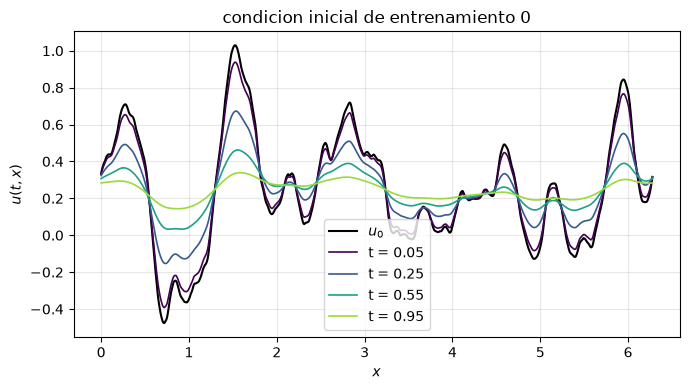

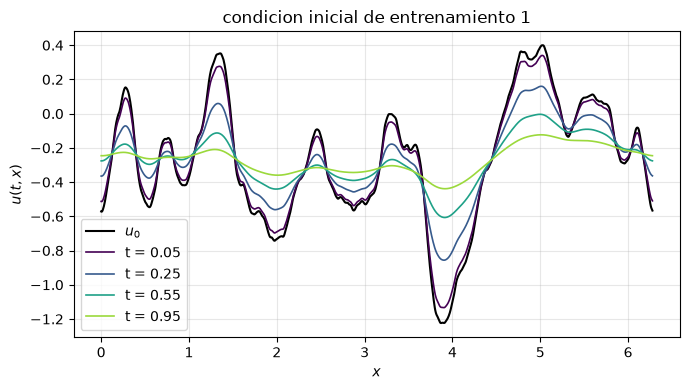

In [6]:
exp_0_5.initial_conditions()

## 2. PDNO guardado

El PDNO no se reentrena: se carga el `modelo.pt` que eligio `08_pdno_fraccionario_1d.ipynb` y se comprueba que es de los mismos datos, en `DTYPE` y con la misma `TRAIN_CONFIG` (salvo el weight decay, que es un eje de su barrido), y que su error de prueba coincide con el de su `prueba.csv`. Si falta `modelo.pt`, la celda falla y dice que notebook correr. Se muestran su banda $(c,C)$, $\kappa$ y las $C_\alpha$ con que se entreno.

In [7]:
resumen_pdno, class_C = exp_0_5.load_pdno()
display(resumen_pdno.to_frame())
display(class_C)

PDNO cargado de ../results/08_pdno_fraccionario_1d/alpha_0.5/modelo.pt
MLP del simbolo        = (128, 128, 128, 128), sin dropout, weight decay 0
(c, C) = (0.7568, 1.0999), m = 0.5, kappa = theoretical_kappa() = 2.0000
mejor epoca            = 299 de 300
error de prueba        = 1.350840e-05 (recalculado) | 1.350840e-05 (prueba.csv) | coincide: True


,PDNO guardado
c,0.756807
C,1.099933
m,0.5
kappa,2.0
mlp_simbolo,"(128, 128, 128, 128)"
weight_decay,0.0
parametros,49921
mejor_epoca,299
epocas,300
rel_l2_prueba (recalculado),0.000014


,C_alpha usadas (x1.5)
alpha,
"(0,)",1.499908
"(1,)",1.783811
"(2,)",5.045379


## 3. Barridos y seleccion

### 3.1 PDNO

El barrido de la MLP del simbolo de `08_pdno_fraccionario_1d.ipynb` (su `barrido.csv`), de mejor a peor $L^2$ relativa de validacion; la corrida elegida es la primera.

In [8]:
display(exp_0_5.pdno_sweep())

barrido del PDNO de ../results/08_pdno_fraccionario_1d/alpha_0.5/barrido.csv: 30 corridas, 35.1 min de entrenamiento en total


,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,val_par_max_ratio
0,4,128,OFF,0.0000,0.000015,0.000015,0.594525
1,4,128,OFF,0.0001,0.000021,0.000021,0.594512
2,3,128,OFF,0.0000,0.000255,0.000255,0.594508
3,3,128,OFF,0.0001,0.000265,0.000265,0.594503
4,3,32,OFF,0.0001,0.000292,0.000292,0.594504
5,3,32,OFF,0.0000,0.000296,0.000296,0.594492
6,2,32,OFF,0.0000,0.000299,0.000299,0.594503
7,2,32,OFF,0.0001,0.000299,0.000299,0.594503
8,3,64,OFF,0.0000,0.000301,0.000301,0.594504
9,3,64,OFF,0.0001,0.000301,0.000301,0.594504


### 3.2 FNO

`FNOBaseline` envuelve el `FNO` de `neuraloperator` 2.0.0 con la interfaz del PDNO, `forward(u0, t)`, como en `10_benchmark_calor_1d.ipynb`: entrada $u_0(x)$ y $t$ constante, embedding de posicion `"grid"`, salida $u(t)$, sin `domain_padding`. La libreria conserva $|k|\le$ `n_modes`$/2$: con $128$ el FNO ve la misma ventana $|k|\le64$ que las filas espectrales del PDNO, y con $256$, $|k|\le128$. Cada corrida es `train_baseline` con `TRAIN_CONFIG` y weight decay $0$ (misma perdida, optimizador y early stopping que el PDNO, sin los terminos del simbolo); se elige la de **menor $L^2$ relativa de validacion**.

In [9]:
exp_0_5.sweep_fno()

[  1/24] n_modes=8   hidden=32  capas=2 | rel_l2=0.1082 |  40.9s
[  2/24] n_modes=8   hidden=32  capas=4 | rel_l2=0.0804 |  61.8s
[  3/24] n_modes=8   hidden=64  capas=2 | rel_l2=0.0827 |  73.5s
[  4/24] n_modes=8   hidden=64  capas=4 | rel_l2=0.0581 | 147.6s
[  5/24] n_modes=16  hidden=32  capas=2 | rel_l2=0.0683 |  48.2s
[  6/24] n_modes=16  hidden=32  capas=4 | rel_l2=0.1090 | 168.7s
[  7/24] n_modes=16  hidden=64  capas=2 | rel_l2=0.0276 |  86.6s
[  8/24] n_modes=16  hidden=64  capas=4 | rel_l2=0.0302 | 166.5s
[  9/24] n_modes=32  hidden=32  capas=2 | rel_l2=0.1614 |  89.6s
[ 10/24] n_modes=32  hidden=32  capas=4 | rel_l2=0.2201 |  77.5s
[ 11/24] n_modes=32  hidden=64  capas=2 | rel_l2=0.0391 | 129.3s
[ 12/24] n_modes=32  hidden=64  capas=4 | rel_l2=0.0463 | 220.6s
[ 13/24] n_modes=64  hidden=32  capas=2 | rel_l2=0.0696 |  37.9s
[ 14/24] n_modes=64  hidden=32  capas=4 | rel_l2=0.0294 |  75.7s
[ 15/24] n_modes=64  hidden=64  capas=2 | rel_l2=0.0334 |  63.3s
[ 16/24] n_modes=64  hidd

In [10]:
barrido_fno, por_eje = exp_0_5.sweep_fno_results()
display(barrido_fno)
for tabla in por_eje:
    display(tabla)

,n_modes,k_max_fno,hidden_channels,capas,parametros,val_rel_l2,mejor_epoca,epocas,segundos
0,128,64,64,2,1099009,0.013955,292,300,194.525112
1,256,128,64,2,2147585,0.016995,190,250,177.876351
2,256,128,64,4,4277953,0.021662,213,273,346.498262
3,16,8,64,2,181505,0.027602,84,144,86.629679
4,64,32,32,4,283489,0.029406,72,132,75.707406
5,16,8,64,4,345793,0.030247,99,159,166.540635
6,64,32,64,4,1132225,0.030405,81,141,153.436858
7,128,64,64,4,2180801,0.033145,297,300,342.816636
8,64,32,64,2,574721,0.033372,42,102,63.349260
9,32,16,64,2,312577,0.039099,153,213,129.277352


,corridas,mejor_val_rel_l2
n_modes,,
8,4,0.058106
16,4,0.027602
32,4,0.039099
64,4,0.029406
128,4,0.013955
256,4,0.016995


,corridas,mejor_val_rel_l2
hidden_channels,,
32,12,0.029406
64,12,0.013955


,corridas,mejor_val_rel_l2
capas,,
2,12,0.013955
4,12,0.021662


In [11]:
display(exp_0_5.select_fno().to_frame())

arquitectura elegida    = n_modes 128 (|k| <= 64), hidden_channels 64, 2 capas
parametros              = 1,099,009 (reales; un peso complejo cuenta como dos)
early stopping          = mejor epoca 292 de 300 epocas; se detuvo antes del final: False
rel_l2 de validacion    = 0.0140


,FNO elegido
n_modes,1.280000e+02
hidden_channels,6.400000e+01
capas,2.000000e+00
parametros,1.099009e+06
mejor_epoca,2.920000e+02
epocas,3.000000e+02
val_rel_l2,1.395513e-02


### 3.3 Curvas de entrenamiento

Las dos corridas elegidas, por epoca, en entrenamiento y validacion y en escala log, una imagen por termino. PDNO: perdida total y cada termino, leidos de `historia.csv` de su notebook (`perdida_pdno_*.png`). FNO: su unico termino, la $L^2$ relativa (`perdida_fno_rel_l2.png`). La linea punteada marca la epoca restaurada por el early stopping.

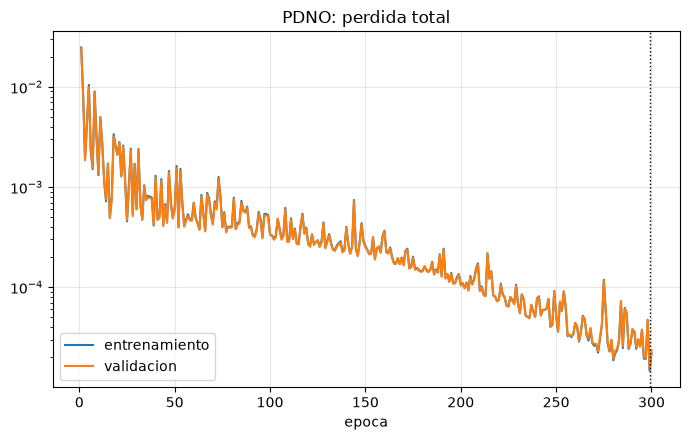

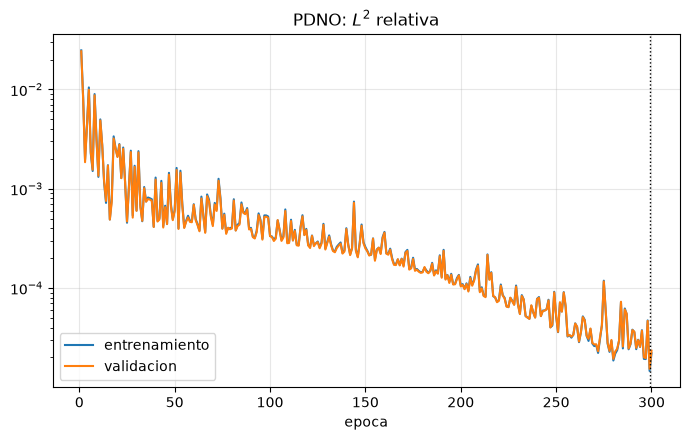

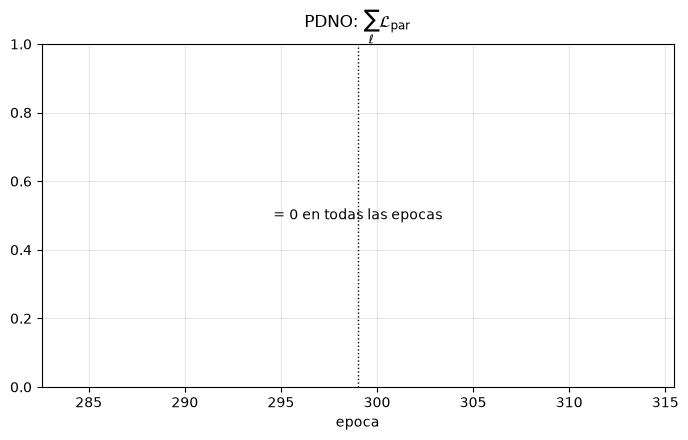

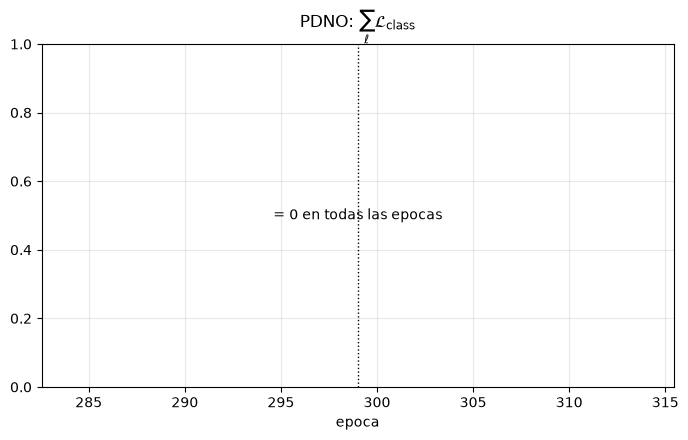

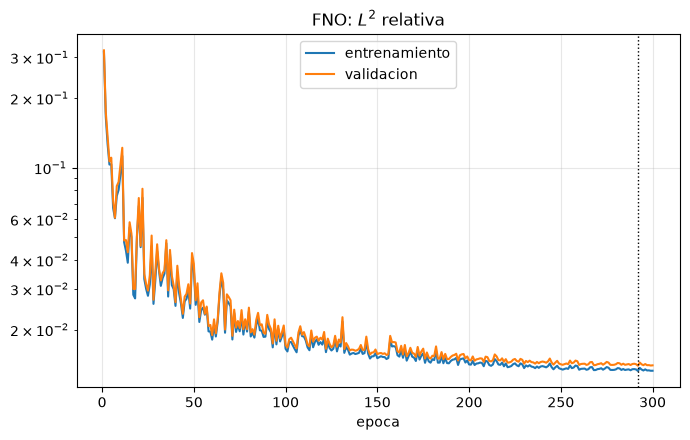

In [12]:
exp_0_5.curves()

## 4. Prueba

Error relativo $L^2$ de cada condicion inicial de prueba y tiempo de `TEST_TIMES`, media y maximo por tiempo, para los dos modelos en la misma tabla y la misma figura. Los tiempos que no estan en `TRAIN_TIMES` van con circulos y lineas grises.

PRUEBA -- 20 condiciones iniciales nuevas x 20 tiempos
  PDNO: error relativo L2 = 1.3508e-05  (medio; max 2.7152e-05)
  FNO: error relativo L2 = 1.4497e-02  (medio; max 4.3132e-02)


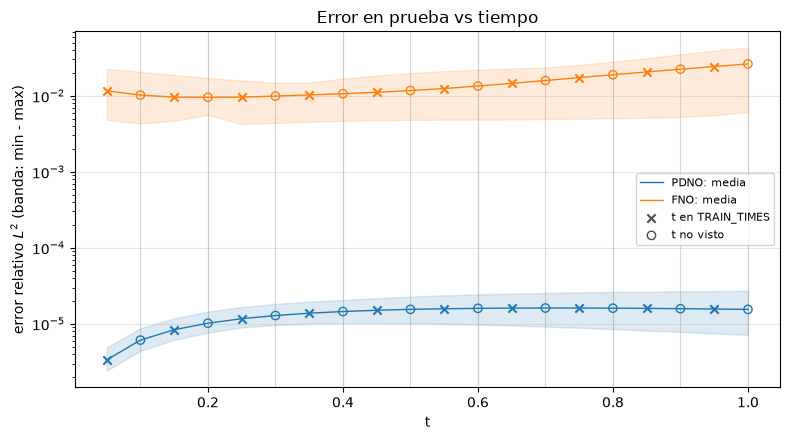

PDNO                 FNO                           
           media       max     media       max en_entrenamiento
t                                                              
0.05    0.000003  0.000005  0.011587  0.022623             True
0.10    0.000006  0.000009  0.010199  0.020612            False
0.15    0.000008  0.000012  0.009589  0.018792             True
0.20    0.000010  0.000014  0.009551  0.017174            False
0.25    0.000012  0.000017  0.009599  0.015833             True
0.30    0.000013  0.000018  0.009901  0.014819            False
0.35    0.000014  0.000020  0.010245  0.014893             True
0.40    0.000014  0.000020  0.010632  0.016795            False
0.45    0.000015  0.000022  0.011097  0.018466             True
0.50    0.000015  0.000023  0.011691  0.019899            False
0.55    0.000016  0.000024  0.012455  0.021095             True
0.60    0.000016  0.000024  0.013409  0.022077            False
0.65    0.000016  0.000025  0.014549  0.022873             True
0.70    0.000016  0.000025  0.015858  0.023503            False
0.75    0.000016  0.000026  0.017315  0.025475             True
0.80    0.000016  0.000026  0.018892  0.028129            False
0.85    0.000016  0.000026  0.020570  0.031178             True
0.90    0.000016  0.000027  0.022344  0.035050            False
0.95    0.000016  0.000027  0.024223  0.039036             True
1.00    0.000015  0.000027  0.026229  0.043132            False
global  0.000014  0.000027  0.014497  0.043132             None

In [13]:
display(exp_0_5.test())

**Campo.** Primera condicion inicial de prueba en algunos tiempos de `TEST_TIMES`: exacta (continua), PDNO (--) y FNO (-.) en `campo.png`, y el error puntual de cada modelo en `campo_error_pdno.png` y `campo_error_fno.png`.

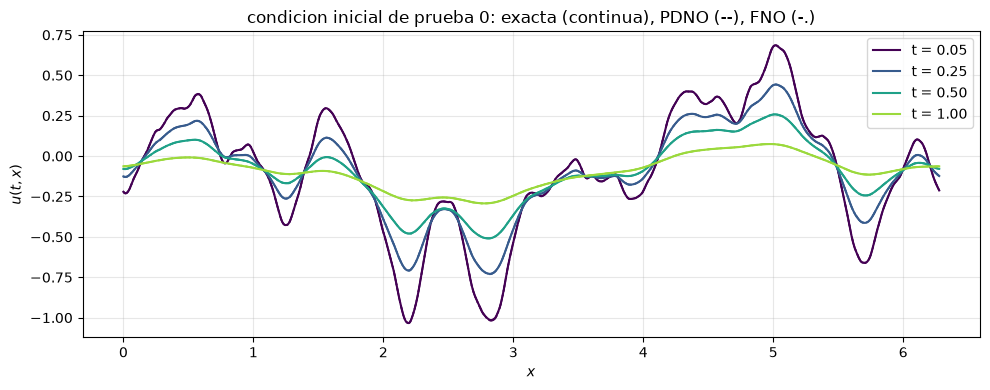

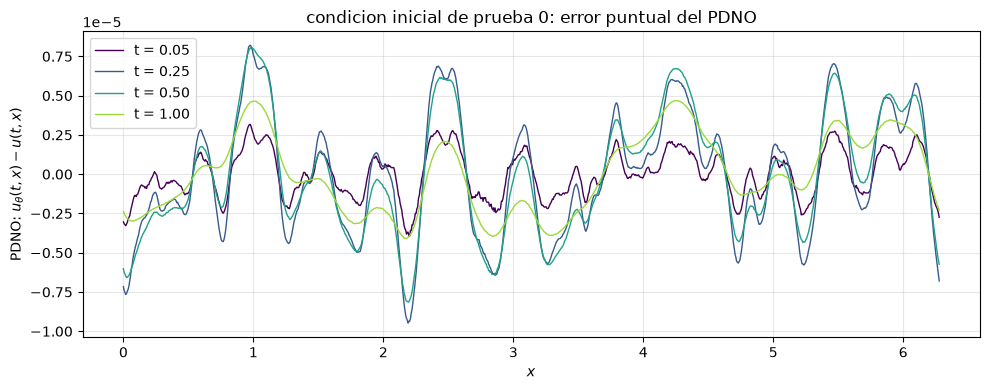

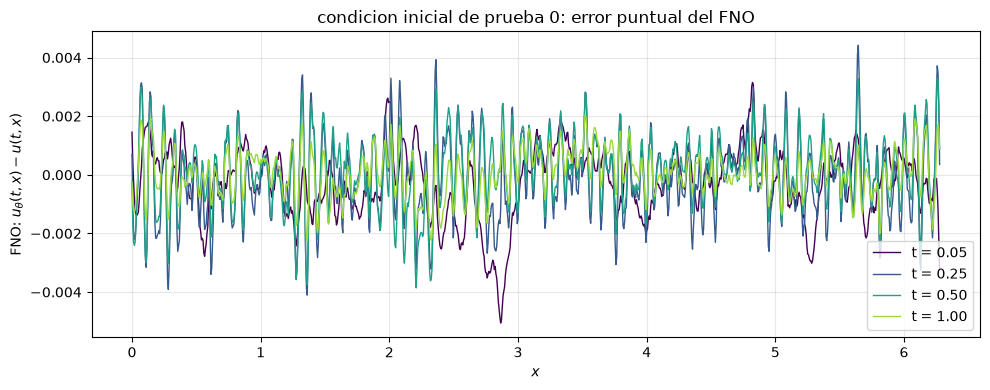

In [14]:
exp_0_5.field_figure()

## 5. Extrapolacion temporal

Las $u_0$ de prueba en `EXTRAPOLATION_TIMES` $\subset(0.95,3]$, fuera del rango de entrenamiento. Solo se reporta: no interviene en el entrenamiento ni en la seleccion.

EXTRAPOLACION -- 20 condiciones iniciales x 21 tiempos en [1, 3]
  PDNO: error relativo L2 = 1.0317e-05  (medio; max 2.8438e-05)
  FNO: error relativo L2 = 1.6457e-01  (medio; max 1.4276e+00)


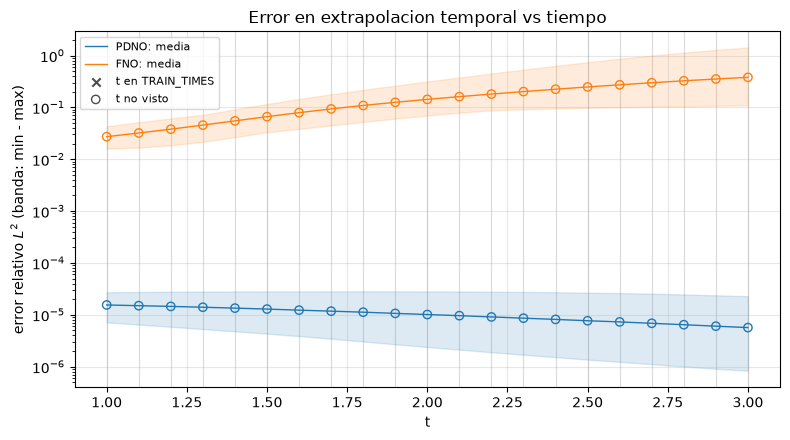

PDNO                 FNO                           
           media       max     media       max en_entrenamiento
t                                                              
1.00    0.000015  0.000027  0.027212  0.043132            False
1.10    0.000015  0.000028  0.032030  0.051762            False
1.20    0.000015  0.000028  0.037980  0.061231            False
1.30    0.000014  0.000028  0.045520  0.071744            False
1.40    0.000013  0.000028  0.054913  0.091575            False
1.50    0.000013  0.000028  0.066166  0.116048            False
1.60    0.000012  0.000028  0.079076  0.144996            False
1.70    0.000012  0.000028  0.093372  0.178566            False
1.80    0.000011  0.000028  0.108816  0.217431            False
1.90    0.000011  0.000028  0.125237  0.262410            False
2.00    0.000010  0.000028  0.142623  0.314912            False
2.10    0.000010  0.000028  0.161037  0.376661            False
2.20    0.000009  0.000028  0.180619  0.449324            False
2.30    0.000009  0.000028  0.201507  0.534282            False
2.40    0.000008  0.000027  0.223810  0.632161            False
2.50    0.000008  0.000027  0.247507  0.742835            False
2.60    0.000007  0.000026  0.272487  0.865263            False
2.70    0.000007  0.000025  0.298543  0.997556            False
2.80    0.000006  0.000025  0.325328  1.137210            False
2.90    0.000006  0.000024  0.352492  1.281815            False
3.00    0.000006  0.000023  0.379620  1.427569            False
global  0.000010  0.000028  0.164566  1.427569             None

In [15]:
display(exp_0_5.extrapolation())

## 6. Invariancia de resolucion

Los dos modelos, entrenados en $1024$, sobre las mismas $u_0$ de prueba en `EVAL_RESOLUTIONS`, como en el 10 (`resample_fields` desde los campos float64 y luego a `DTYPE`): submuestreo hacia las mallas gruesas y relleno con ceros del espectro hacia las finas, que es la solucion exacta de la misma $u_0$. La celda comprueba que submuestrear los campos rellenados devuelve los originales. El PDNO evalua su simbolo en los modos de cada malla; el FNO usa los mismos `n_modes` y recalcula el embedding de posicion.

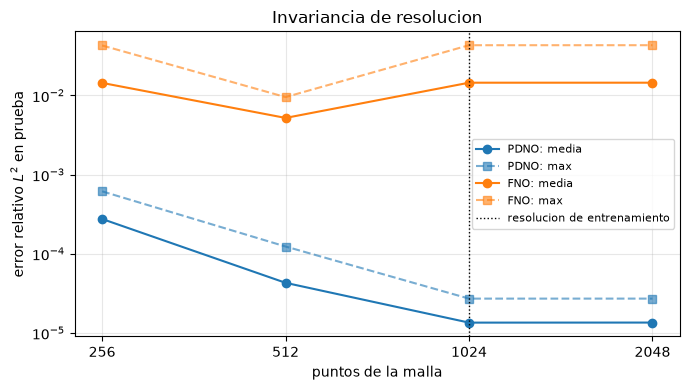

,PDNO media,PDNO max,FNO media,FNO max
resolucion,,,,
256,0.000275,0.000615,0.014412,0.042831
512,0.000043,0.000124,0.005203,0.009541
1024,0.000014,0.000027,0.014497,0.043132
2048,0.000014,0.000027,0.014501,0.043146


In [16]:
display(exp_0_5.resolution_invariance())

## 7. Simbolo y certificacion del PDNO

Las secciones 7 y 8 de `08_pdno_fraccionario_1d.ipynb` con el modelo cargado: simbolo efectivo frente a $|k|^{0.5}$ (`simbolo.png`) y $\bar a(k)/\langle k\rangle^m$ en la banda (`simbolo_banda.png`), su error relativo, la certificacion de parabolicidad (Def. 2.3) y la clase $S^{m,\rho}$ (Def. 2.1). El FNO no tiene simbolo.

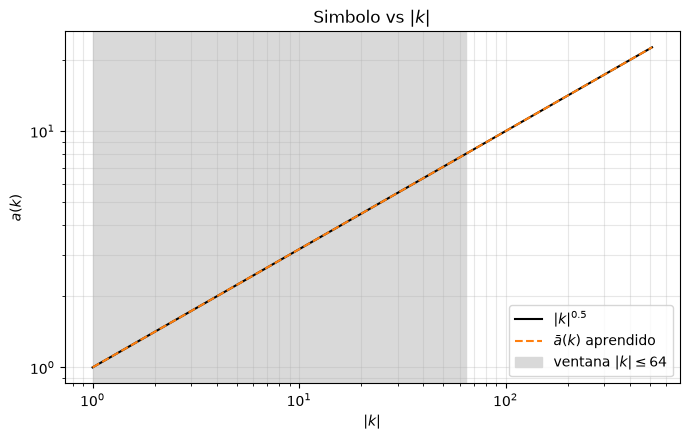

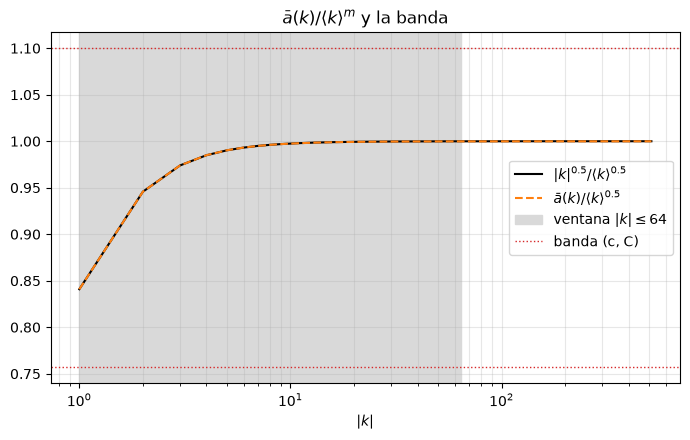

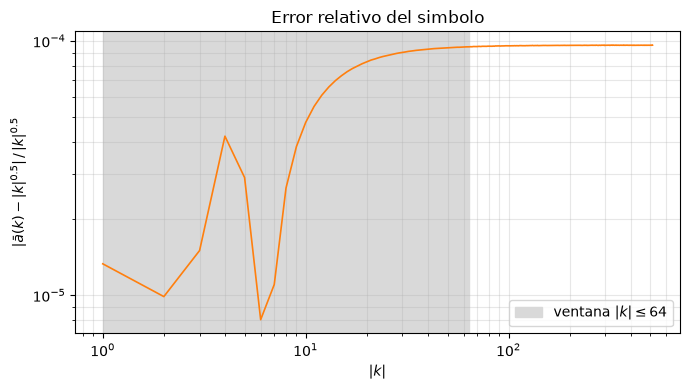

,dentro (|k| <= 64),fuera (|k| > 64)
n,1.290000e+02,896.000000
mse,2.639758e-07,0.000003
rmse,5.137858e-04,0.001632
mae,4.598432e-04,0.001584
max_error,7.581711e-04,0.002177
rel_l2,9.047535e-05,0.000096
error_relativo_medio,7.832723e-05,0.000096
error_relativo_max,9.477139e-05,0.000096


In [17]:
display(exp_0_5.symbol())

In [18]:
display(exp_0_5.certification())

kappa usada = 2.0000


,simbolo,K,region,puntos,max_ratio,satisfecha
0,capa 0,64,dentro,80625,0.594582,True
1,capa 0,128,fuera,160625,0.594582,True
2,capa 0,192,fuera,240625,0.594582,True
3,efectivo,64,dentro,80625,0.594582,True
4,efectivo,128,fuera,160625,0.594582,True
5,efectivo,192,fuera,240625,0.594582,True


In [19]:
display(exp_0_5.symbol_class())

capa 0: consistentes 3 de 3 multiindices
efectivo: consistentes 3 de 3 multiindices
ventana explorada: |k| <= 128 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta


,simbolo,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(128),crecim.(12->128),pendiente,m-|alpha|,estable,consistente
0,capa 0,"(0,)",0,0.985000,0.996105,0.998210,0.999889,1.001682,0.500061,0.5,True,True
1,capa 0,"(1,)",1,1.189191,1.189191,1.189191,1.189191,1.000000,-0.502839,-0.5,True,True
2,capa 0,"(2,)",2,3.363541,3.363541,3.363541,3.363541,1.000000,-1.516895,-1.5,True,True
3,efectivo,"(0,)",0,0.985000,0.996105,0.998210,0.999889,1.001682,0.500061,0.5,True,True
4,efectivo,"(1,)",1,1.189191,1.189191,1.189191,1.189191,1.000000,-0.502839,-0.5,True,True
5,efectivo,"(2,)",2,3.363541,3.363541,3.363541,3.363541,1.000000,-1.516895,-1.5,True,True


## 8. Modelo guardado

`save_fno_model` guarda el FNO elegido en `modelo_fno.pt` (su `FNOConfig`, la version de `neuraloperator`, la `OperatorTrainingConfig` y la misma entrada de datos que el PDNO). El PDNO ya esta guardado en su notebook. La ultima celda recarga el FNO y comprueba que da el mismo error de prueba.

In [20]:
exp_0_5.save_fno()

modelo guardado en ../results/12_benchmark_fraccionario_1d/alpha_0.5/modelo_fno.pt


PosixPath('../results/12_benchmark_fraccionario_1d/alpha_0.5/modelo_fno.pt')

In [21]:
exp_0_5.check_saved_fno()

FNO: error de prueba (cargado) = 1.449670e-02  |  (entrenado) = 1.449670e-02  |  identicos: True


True

# $\alpha = 1$

$a(k)=|k|^{1}$, $m=1$, malla $1024$ puntos. PDNO de `results/08_pdno_fraccionario_1d/alpha_1/`; tablas y figuras en `results/12_benchmark_fraccionario_1d/alpha_1/`. Si 1.0 no esta en `ALPHAS`, esta seccion falla en la primera celda.

In [22]:
exp_1_0 = experimentos[1.0]

## 1. Datos

In [23]:
display(exp_1_0.load_data())

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
CAMPOS (condicion inicial x tiempo)
  train        : 80 u0 x 10 tiempos = 800 pares, malla (1024,)
  val          : 20 u0 x 10 tiempos = 200 pares, malla (1024,)
  test         : 20 u0 x 20 tiempos = 400 pares, malla (1024,)
  extrapolation: 20 u0 x 21 tiempos = 420 pares, malla (1024,)

k_max = k_cap = 64
entrenamiento :  80 condiciones iniciales x 10 tiempos =  800 pares
validacion    :  20 condiciones iniciales x 10 tiempos =  200 pares
prueba        :  20 condiciones iniciales x 20 tiempos =  400 pares
extrapolacion :  20 condiciones iniciales x 21 tiempos =  420 pares
prueba: min ||u0_prueba - u0_vista|| / ||u0_prueba|| = 1.007  (> 0: d

,condiciones_iniciales,tiempos,pares,t_min,t_max
conjunto,,,,,
entrenamiento,80,10,800,0.05,0.95
validacion,20,10,200,0.05,0.95
prueba,20,20,400,0.05,1.00
extrapolacion,20,21,420,1.00,3.00


**Condiciones iniciales y evolucion.**

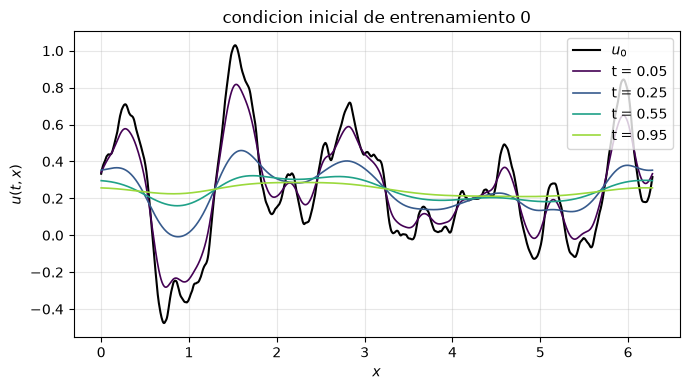

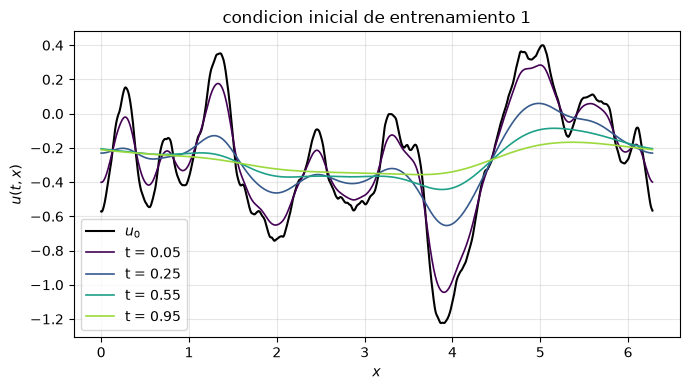

In [24]:
exp_1_0.initial_conditions()

## 2. PDNO guardado

In [25]:
resumen_pdno, class_C = exp_1_0.load_pdno()
display(resumen_pdno.to_frame())
display(class_C)

PDNO cargado de ../results/08_pdno_fraccionario_1d/alpha_1/modelo.pt
MLP del simbolo        = (128, 128, 128, 128), sin dropout, weight decay 0.0001
(c, C) = (0.6364, 1.0999), m = 1, kappa = theoretical_kappa() = 2.2222
mejor epoca            = 275 de 300
error de prueba        = 3.742844e-05 (recalculado) | 3.742844e-05 (prueba.csv) | coincide: True


,PDNO guardado
c,0.636396
C,1.099866
m,1.0
kappa,2.222222
mlp_simbolo,"(128, 128, 128, 128)"
weight_decay,0.0001
parametros,49921
mejor_epoca,275
epocas,300
rel_l2_prueba (recalculado),0.000037


,C_alpha usadas (x1.5)
alpha,
"(0,)",1.499817
"(1,)",1.500003
"(2,)",4.242641


## 3. Barridos y seleccion

### 3.1 PDNO

In [26]:
display(exp_1_0.pdno_sweep())

barrido del PDNO de ../results/08_pdno_fraccionario_1d/alpha_1/barrido.csv: 30 corridas, 36.3 min de entrenamiento en total


,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,val_par_max_ratio
0,4,128,OFF,0.0001,0.000045,0.000045,0.636347
1,4,128,OFF,0.0000,0.000046,0.000046,0.636334
2,4,64,OFF,0.0001,0.000681,0.000681,0.636304
3,4,64,OFF,0.0000,0.000693,0.000693,0.636305
4,3,128,OFF,0.0000,0.000728,0.000728,0.636324
5,3,128,OFF,0.0001,0.000733,0.000733,0.636323
6,3,32,OFF,0.0000,0.000833,0.000833,0.636341
7,3,64,OFF,0.0001,0.000836,0.000836,0.636367
8,3,64,OFF,0.0000,0.000836,0.000836,0.636357
9,2,64,OFF,0.0001,0.000838,0.000838,0.636323


### 3.2 FNO

In [27]:
exp_1_0.sweep_fno()

[  1/24] n_modes=8   hidden=32  capas=2 | rel_l2=0.1163 |  25.9s
[  2/24] n_modes=8   hidden=32  capas=4 | rel_l2=0.1036 |  51.6s
[  3/24] n_modes=8   hidden=64  capas=2 | rel_l2=0.0967 | 115.4s
[  4/24] n_modes=8   hidden=64  capas=4 | rel_l2=0.0561 | 220.4s
[  5/24] n_modes=16  hidden=32  capas=2 | rel_l2=0.1563 |  47.3s
[  6/24] n_modes=16  hidden=32  capas=4 | rel_l2=0.1160 |  60.7s
[  7/24] n_modes=16  hidden=64  capas=2 | rel_l2=0.0294 | 110.1s
[  8/24] n_modes=16  hidden=64  capas=4 | rel_l2=0.0262 | 275.5s
[  9/24] n_modes=32  hidden=32  capas=2 | rel_l2=0.2515 |  45.3s
[ 10/24] n_modes=32  hidden=32  capas=4 | rel_l2=0.2169 |  85.3s
[ 11/24] n_modes=32  hidden=64  capas=2 | rel_l2=0.0443 | 125.0s
[ 12/24] n_modes=32  hidden=64  capas=4 | rel_l2=0.0401 | 207.9s
[ 13/24] n_modes=64  hidden=32  capas=2 | rel_l2=0.0592 |  32.0s
[ 14/24] n_modes=64  hidden=32  capas=4 | rel_l2=0.0968 |  55.1s
[ 15/24] n_modes=64  hidden=64  capas=2 | rel_l2=0.0399 |  78.9s
[ 16/24] n_modes=64  hidd

In [28]:
barrido_fno, por_eje = exp_1_0.sweep_fno_results()
display(barrido_fno)
for tabla in por_eje:
    display(tabla)

,n_modes,k_max_fno,hidden_channels,capas,parametros,val_rel_l2,mejor_epoca,epocas,segundos
0,256,128,64,2,2147585,0.024028,215,275,195.581523
1,128,64,64,2,1099009,0.024659,194,254,164.687725
2,16,8,64,4,345793,0.026180,203,263,275.485727
3,256,128,64,4,4277953,0.028075,259,300,380.812667
4,16,8,64,2,181505,0.029428,123,183,110.070634
5,64,32,64,4,1132225,0.032521,77,137,149.047614
6,64,32,64,2,574721,0.039925,67,127,78.872534
7,32,16,64,4,607937,0.040077,136,196,207.907243
8,32,16,64,2,312577,0.044311,146,206,124.985902
9,128,64,64,4,2180801,0.045660,297,300,342.877151


,corridas,mejor_val_rel_l2
n_modes,,
8,4,0.056066
16,4,0.026180
32,4,0.040077
64,4,0.032521
128,4,0.024659
256,4,0.024028


,corridas,mejor_val_rel_l2
hidden_channels,,
32,12,0.051181
64,12,0.024028


,corridas,mejor_val_rel_l2
capas,,
2,12,0.024028
4,12,0.026180


In [29]:
display(exp_1_0.select_fno().to_frame())

arquitectura elegida    = n_modes 256 (|k| <= 128), hidden_channels 64, 2 capas
parametros              = 2,147,585 (reales; un peso complejo cuenta como dos)
early stopping          = mejor epoca 215 de 275 epocas; se detuvo antes del final: True
rel_l2 de validacion    = 0.0240


,FNO elegido
n_modes,2.560000e+02
hidden_channels,6.400000e+01
capas,2.000000e+00
parametros,2.147585e+06
mejor_epoca,2.150000e+02
epocas,2.750000e+02
val_rel_l2,2.402789e-02


### 3.3 Curvas de entrenamiento

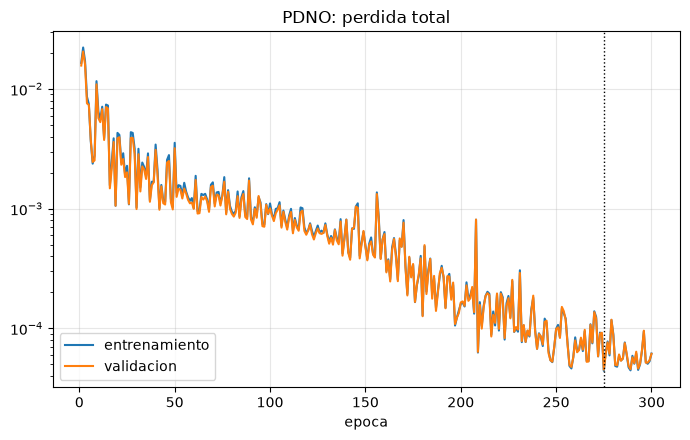

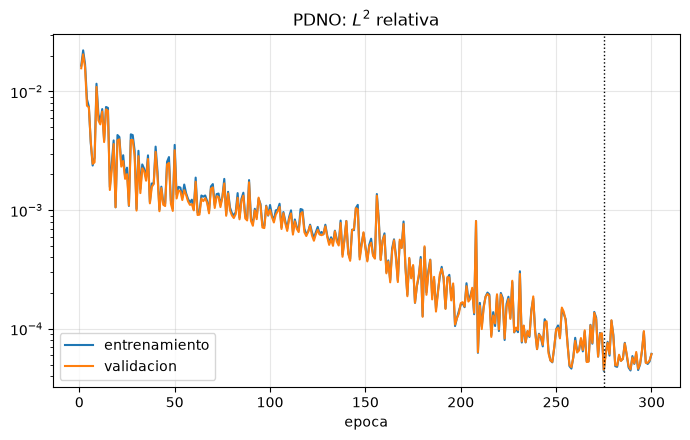

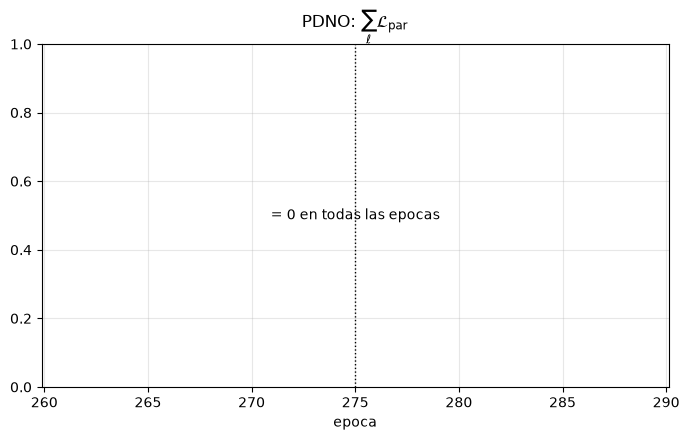

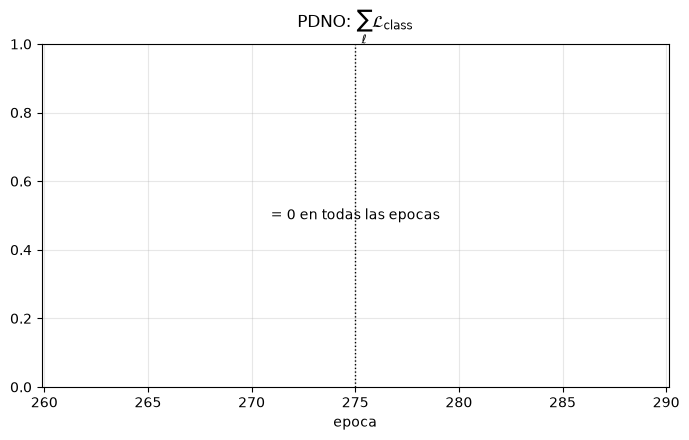

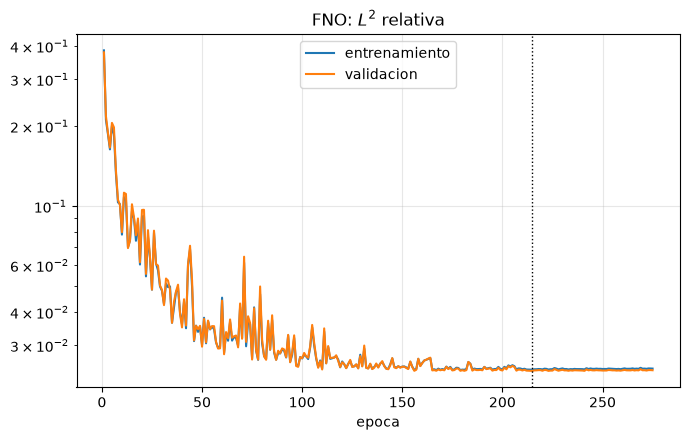

In [30]:
exp_1_0.curves()

## 4. Prueba

PRUEBA -- 20 condiciones iniciales nuevas x 20 tiempos
  PDNO: error relativo L2 = 3.7428e-05  (medio; max 1.1604e-04)
  FNO: error relativo L2 = 2.3104e-02  (medio; max 5.3207e-02)


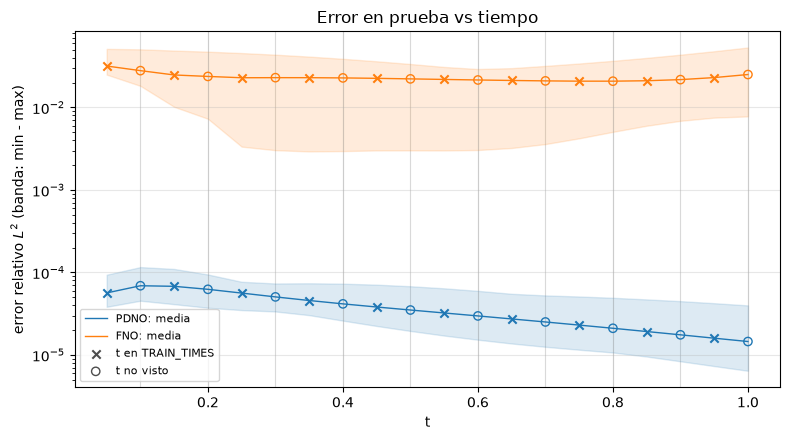

PDNO                 FNO                           
           media       max     media       max en_entrenamiento
t                                                              
0.05    0.000056  0.000094  0.031735  0.051195             True
0.10    0.000069  0.000116  0.027893  0.050545            False
0.15    0.000068  0.000110  0.024725  0.048831             True
0.20    0.000062  0.000094  0.023732  0.047348            False
0.25    0.000056  0.000077  0.022878  0.045561             True
0.30    0.000051  0.000073  0.022932  0.043536            False
0.35    0.000046  0.000074  0.022917  0.041277             True
0.40    0.000042  0.000073  0.022771  0.038811            False
0.45    0.000038  0.000071  0.022503  0.036219             True
0.50    0.000035  0.000068  0.022168  0.033579            False
0.55    0.000032  0.000064  0.021821  0.030926             True
0.60    0.000030  0.000060  0.021495  0.029178            False
0.65    0.000027  0.000055  0.021203  0.029915             True
0.70    0.000025  0.000053  0.020959  0.031833            False
0.75    0.000023  0.000051  0.020798  0.034049             True
0.80    0.000021  0.000049  0.020790  0.036679            False
0.85    0.000019  0.000047  0.021043  0.039821             True
0.90    0.000018  0.000045  0.021711  0.043530            False
0.95    0.000016  0.000042  0.022977  0.047935             True
1.00    0.000015  0.000040  0.025027  0.053207            False
global  0.000037  0.000116  0.023104  0.053207             None

In [31]:
display(exp_1_0.test())

**Campo.**

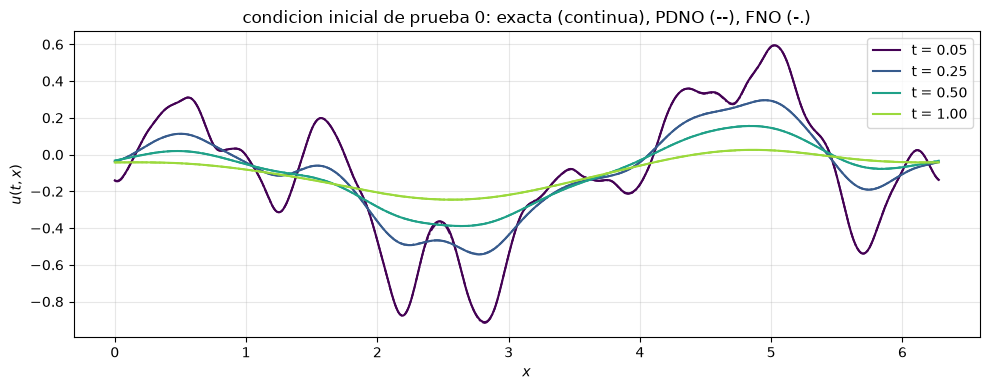

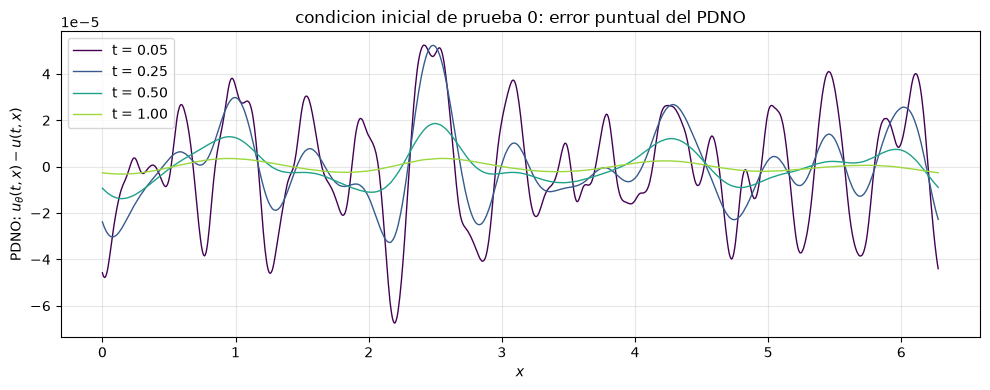

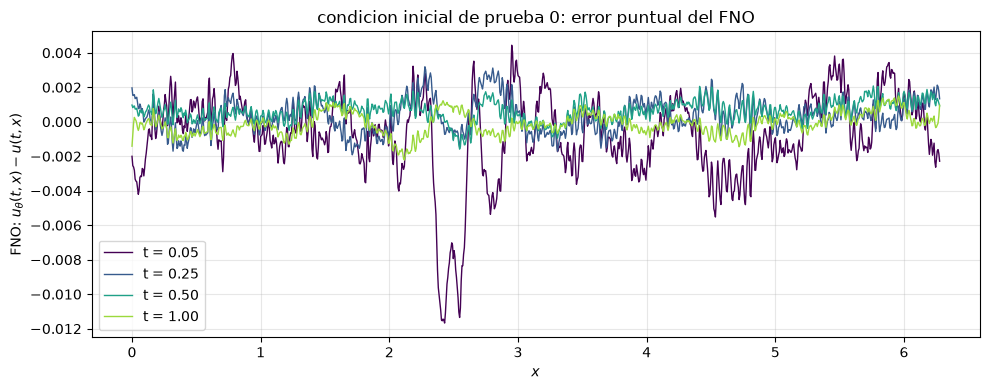

In [32]:
exp_1_0.field_figure()

## 5. Extrapolacion temporal

EXTRAPOLACION -- 20 condiciones iniciales x 21 tiempos en [1, 3]
  PDNO: error relativo L2 = 5.0700e-06  (medio; max 3.9853e-05)
  FNO: error relativo L2 = 1.0163e+00  (medio; max 1.1748e+01)


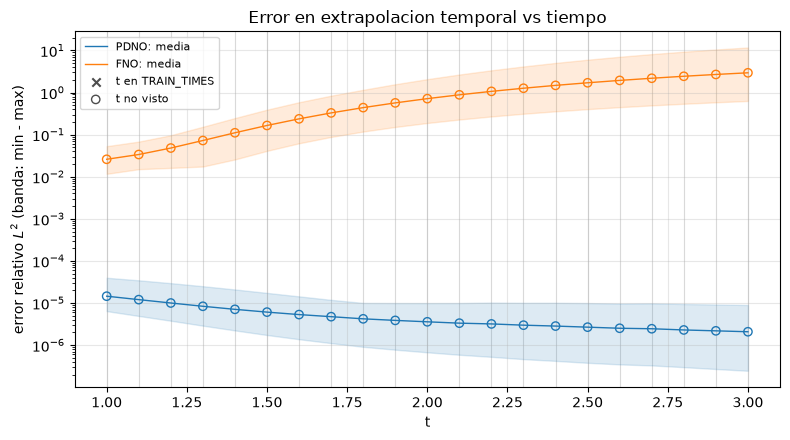

PDNO                 FNO                            
           media       max     media        max en_entrenamiento
t                                                               
1.00    0.000015  0.000040  0.025983   0.053207            False
1.10    0.000012  0.000035  0.033731   0.068284            False
1.20    0.000010  0.000030  0.048062   0.096809            False
1.30    0.000008  0.000025  0.072544   0.153750            False
1.40    0.000007  0.000021  0.110756   0.247629            False
1.50    0.000006  0.000017  0.165120   0.391354            False
1.60    0.000005  0.000014  0.237249   0.588635            False
1.70    0.000005  0.000012  0.328164   0.841366            False
1.80    0.000004  0.000010  0.438358   1.160382            False
1.90    0.000004  0.000010  0.567871   1.574477            False
2.00    0.000004  0.000010  0.716313   2.078840            False
2.10    0.000003  0.000010  0.882919   2.677877            False
2.20    0.000003  0.000010  1.066671   3.374374            False
2.30    0.000003  0.000010  1.266190   4.167272            False
2.40    0.000003  0.000010  1.479874   5.053278            False
2.50    0.000003  0.000010  1.705804   6.024521            False
2.60    0.000003  0.000010  1.941945   7.071477            False
2.70    0.000002  0.000010  2.186071   8.181656            False
2.80    0.000002  0.000009  2.435895   9.341045            False
2.90    0.000002  0.000009  2.689221  10.534945            False
3.00    0.000002  0.000009  2.943853  11.747807            False
global  0.000005  0.000040  1.016314  11.747807             None

In [33]:
display(exp_1_0.extrapolation())

## 6. Invariancia de resolucion

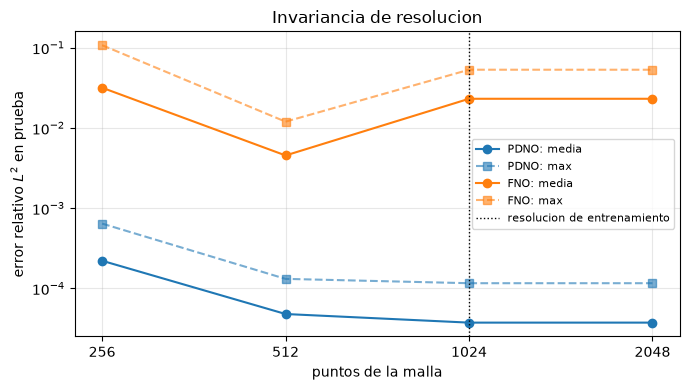

,PDNO media,PDNO max,FNO media,FNO max
resolucion,,,,
256,0.000221,0.000642,0.031733,0.107531
512,0.000048,0.000131,0.004540,0.011976
1024,0.000037,0.000116,0.023104,0.053207
2048,0.000037,0.000116,0.023108,0.053185


In [34]:
display(exp_1_0.resolution_invariance())

## 7. Simbolo y certificacion del PDNO

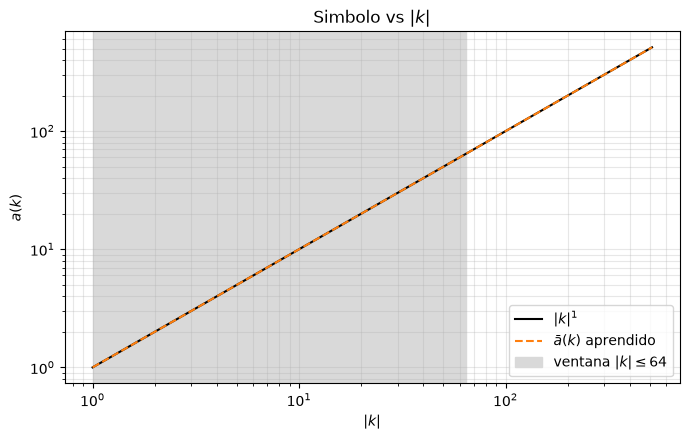

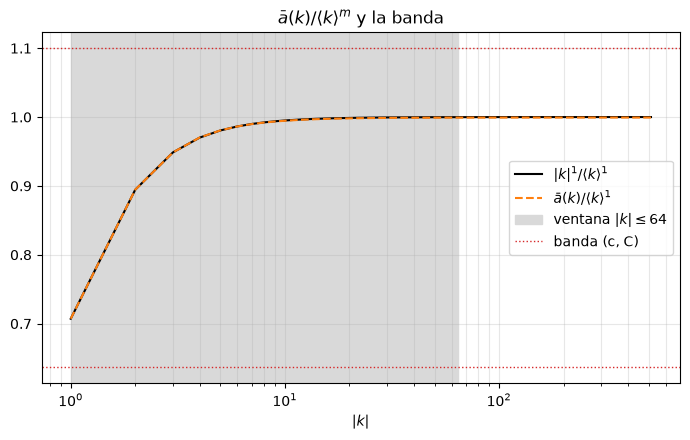

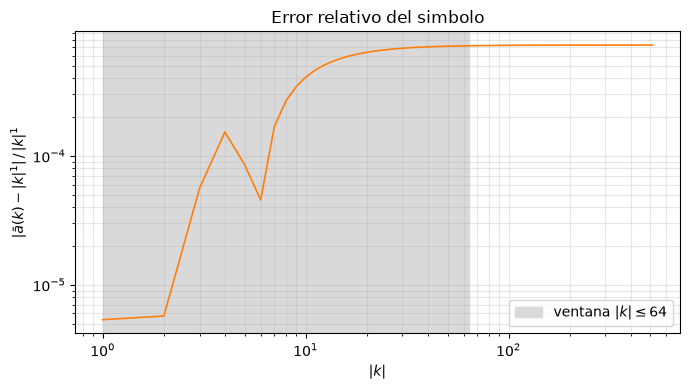

,dentro (|k| <= 64),fuera (|k| > 64)
n,129.000000,896.000000
mse,0.000684,0.052459
rmse,0.026154,0.229039
mae,0.021950,0.208937
max_error,0.045822,0.371033
rel_l2,0.000702,0.000724
error_relativo_medio,0.000592,0.000724
error_relativo_max,0.000716,0.000725


In [35]:
display(exp_1_0.symbol())

In [36]:
display(exp_1_0.certification())

kappa usada = 2.2222


,simbolo,K,region,puntos,max_ratio,satisfecha
0,capa 0,64,dentro,80625,0.636377,True
1,capa 0,128,fuera,160625,0.636377,True
2,capa 0,192,fuera,240625,0.636377,True
3,efectivo,64,dentro,80625,0.636377,True
4,efectivo,128,fuera,160625,0.636377,True
5,efectivo,192,fuera,240625,0.636377,True


In [37]:
display(exp_1_0.symbol_class())

capa 0: consistentes 2 de 3 multiindices
efectivo: consistentes 2 de 3 multiindices
ventana explorada: |k| <= 128 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta


,simbolo,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(128),crecim.(12->128),pendiente,m-|alpha|,estable,consistente
0,capa 0,"(0,)",0,0.970291,0.992012,0.996053,0.999247,1.003207,1.000116,1.0,True,True
1,capa 0,"(1,)",1,1.000782,1.000782,1.000782,1.000782,1.000000,0.000010,0.0,True,True
2,capa 0,"(2,)",2,2.828442,2.828442,2.828442,2.828442,1.000000,-0.171865,-1.0,True,False
3,efectivo,"(0,)",0,0.970291,0.992012,0.996053,0.999247,1.003207,1.000116,1.0,True,True
4,efectivo,"(1,)",1,1.000782,1.000782,1.000782,1.000782,1.000000,0.000010,0.0,True,True
5,efectivo,"(2,)",2,2.828442,2.828442,2.828442,2.828442,1.000000,-0.171865,-1.0,True,False


## 8. Modelo guardado

In [38]:
exp_1_0.save_fno()

modelo guardado en ../results/12_benchmark_fraccionario_1d/alpha_1/modelo_fno.pt


PosixPath('../results/12_benchmark_fraccionario_1d/alpha_1/modelo_fno.pt')

In [39]:
exp_1_0.check_saved_fno()

FNO: error de prueba (cargado) = 2.310398e-02  |  (entrenado) = 2.310398e-02  |  identicos: True


True

# $\alpha = 1.5$

$a(k)=|k|^{1.5}$, $m=1.5$, malla $1024$ puntos. PDNO de `results/08_pdno_fraccionario_1d/alpha_1.5/`; tablas y figuras en `results/12_benchmark_fraccionario_1d/alpha_1.5/`. Si 1.5 no esta en `ALPHAS`, esta seccion falla en la primera celda.

In [40]:
exp_1_5 = experimentos[1.5]

## 1. Datos

In [41]:
display(exp_1_5.load_data())

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
CAMPOS (condicion inicial x tiempo)
  train        : 80 u0 x 10 tiempos = 800 pares, malla (1024,)
  val          : 20 u0 x 10 tiempos = 200 pares, malla (1024,)
  test         : 20 u0 x 20 tiempos = 400 pares, malla (1024,)
  extrapolation: 20 u0 x 21 tiempos = 420 pares, malla (1024,)

k_max = k_cap = 64
entrenamiento :  80 condiciones iniciales x 10 tiempos =  800 pares
validacion    :  20 condiciones iniciales x 10 tiempos =  200 pares
prueba        :  20 condiciones iniciales x 20 tiempos =  400 pares
extrapolacion :  20 condiciones iniciales x 21 tiempos =  420 pares
prueba: min ||u0_prueba - u0_vista|| / ||u0_prueba|| = 1.007  (> 0: d

,condiciones_iniciales,tiempos,pares,t_min,t_max
conjunto,,,,,
entrenamiento,80,10,800,0.05,0.95
validacion,20,10,200,0.05,0.95
prueba,20,20,400,0.05,1.00
extrapolacion,20,21,420,1.00,3.00


**Condiciones iniciales y evolucion.**

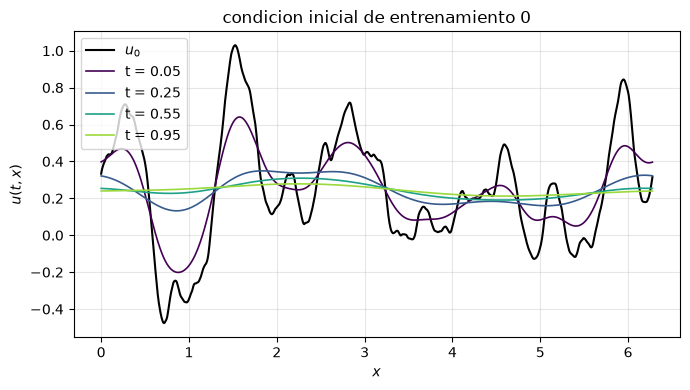

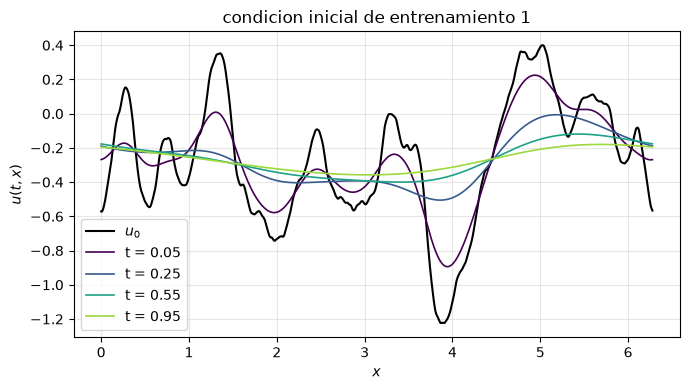

In [42]:
exp_1_5.initial_conditions()

## 2. PDNO guardado

In [43]:
resumen_pdno, class_C = exp_1_5.load_pdno()
display(resumen_pdno.to_frame())
display(class_C)

PDNO cargado de ../results/08_pdno_fraccionario_1d/alpha_1.5/modelo.pt
MLP del simbolo        = (128, 128, 128, 128), sin dropout, weight decay 0
(c, C) = (0.5351, 1.0998), m = 1.5, kappa = theoretical_kappa() = 2.6427
mejor epoca            = 281 de 300
error de prueba        = 1.456459e-05 (recalculado) | 1.456459e-05 (prueba.csv) | coincide: True


,PDNO guardado
c,0.535143
C,1.099763
m,1.5
kappa,2.642682
mlp_simbolo,"(128, 128, 128, 128)"
weight_decay,0.0
parametros,49921
mejor_epoca,281
epocas,300
rel_l2_prueba (recalculado),0.000015


,C_alpha usadas (x1.5)
alpha,
"(0,)",1.499677
"(1,)",2.375090
"(2,)",3.567621


## 3. Barridos y seleccion

### 3.1 PDNO

In [44]:
display(exp_1_5.pdno_sweep())

barrido del PDNO de ../results/08_pdno_fraccionario_1d/alpha_1.5/barrido.csv: 30 corridas, 35.7 min de entrenamiento en total


,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,val_par_max_ratio
0,4,128,OFF,0.0000,0.000019,0.000019,0.655343
1,4,128,OFF,0.0001,0.000024,0.000024,0.655341
2,4,32,OFF,0.0000,0.000112,0.000112,0.655340
3,4,32,OFF,0.0001,0.000122,0.000122,0.655340
4,3,128,OFF,0.0000,0.000437,0.000437,0.655324
5,3,128,OFF,0.0001,0.000529,0.000529,0.655335
6,2,32,OFF,0.0001,0.000911,0.000911,0.655337
7,2,32,OFF,0.0000,0.000912,0.000912,0.655334
8,3,32,OFF,0.0001,0.000962,0.000962,0.655337
9,3,32,OFF,0.0000,0.000962,0.000962,0.655337


### 3.2 FNO

In [45]:
exp_1_5.sweep_fno()

[  1/24] n_modes=8   hidden=32  capas=2 | rel_l2=0.0690 |  58.2s
[  2/24] n_modes=8   hidden=32  capas=4 | rel_l2=0.1006 |  58.9s
[  3/24] n_modes=8   hidden=64  capas=2 | rel_l2=0.0903 | 126.1s
[  4/24] n_modes=8   hidden=64  capas=4 | rel_l2=0.0592 | 311.9s
[  5/24] n_modes=16  hidden=32  capas=2 | rel_l2=0.1740 |  64.7s
[  6/24] n_modes=16  hidden=32  capas=4 | rel_l2=0.1020 |  54.5s
[  7/24] n_modes=16  hidden=64  capas=2 | rel_l2=0.0452 | 117.9s
[  8/24] n_modes=16  hidden=64  capas=4 | rel_l2=0.0237 | 314.2s
[  9/24] n_modes=32  hidden=32  capas=2 | rel_l2=0.2696 |  51.4s
[ 10/24] n_modes=32  hidden=32  capas=4 | rel_l2=0.2290 |  81.4s
[ 11/24] n_modes=32  hidden=64  capas=2 | rel_l2=0.0217 |  97.7s
[ 12/24] n_modes=32  hidden=64  capas=4 | rel_l2=0.0350 | 318.1s
[ 13/24] n_modes=64  hidden=32  capas=2 | rel_l2=0.0510 |  38.6s
[ 14/24] n_modes=64  hidden=32  capas=4 | rel_l2=0.1063 |  68.3s
[ 15/24] n_modes=64  hidden=64  capas=2 | rel_l2=0.0448 |  80.1s
[ 16/24] n_modes=64  hidd

In [46]:
barrido_fno, por_eje = exp_1_5.sweep_fno_results()
display(barrido_fno)
for tabla in por_eje:
    display(tabla)

,n_modes,k_max_fno,hidden_channels,capas,parametros,val_rel_l2,mejor_epoca,epocas,segundos
0,32,16,64,2,312577,0.021668,101,161,97.666068
1,16,8,64,4,345793,0.023694,295,300,314.187836
2,128,64,64,2,1099009,0.026729,194,254,164.651343
3,256,128,64,2,2147585,0.028527,184,244,173.578924
4,256,128,64,4,4277953,0.031633,295,300,380.727675
5,64,32,64,4,1132225,0.034850,143,203,220.828067
6,32,16,64,4,607937,0.034951,298,300,318.142354
7,128,64,32,2,275073,0.043951,52,112,37.665230
8,64,32,64,2,574721,0.044844,69,129,80.087433
9,16,8,64,2,181505,0.045215,136,196,117.857645


,corridas,mejor_val_rel_l2
n_modes,,
8,4,0.059198
16,4,0.023694
32,4,0.021668
64,4,0.034850
128,4,0.026729
256,4,0.028527


,corridas,mejor_val_rel_l2
hidden_channels,,
32,12,0.043951
64,12,0.021668


,corridas,mejor_val_rel_l2
capas,,
2,12,0.021668
4,12,0.023694


In [47]:
display(exp_1_5.select_fno().to_frame())

arquitectura elegida    = n_modes 32 (|k| <= 16), hidden_channels 64, 2 capas
parametros              = 312,577 (reales; un peso complejo cuenta como dos)
early stopping          = mejor epoca 101 de 161 epocas; se detuvo antes del final: True
rel_l2 de validacion    = 0.0217


,FNO elegido
n_modes,32.000000
hidden_channels,64.000000
capas,2.000000
parametros,312577.000000
mejor_epoca,101.000000
epocas,161.000000
val_rel_l2,0.021668


### 3.3 Curvas de entrenamiento

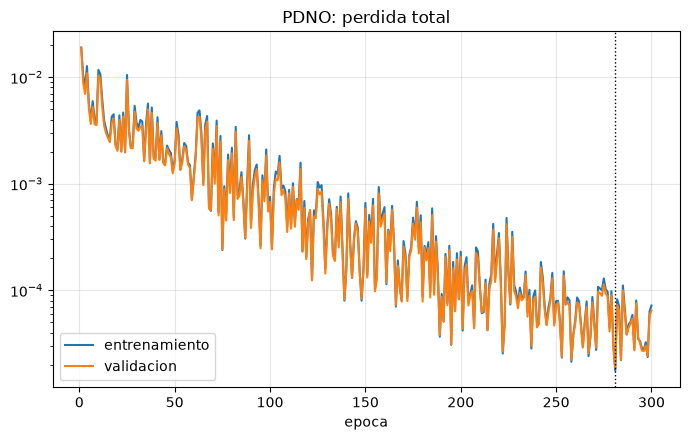

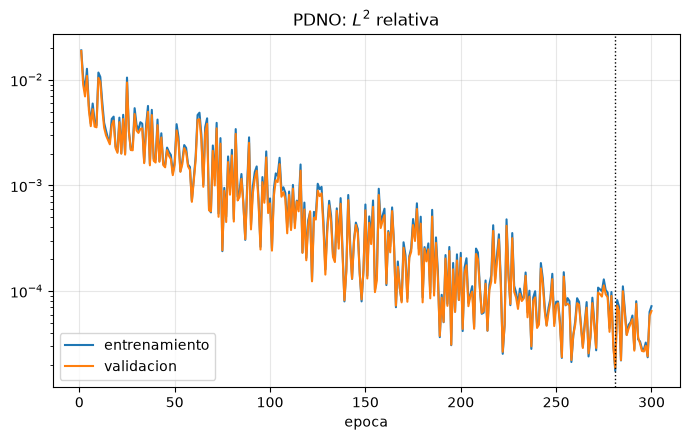

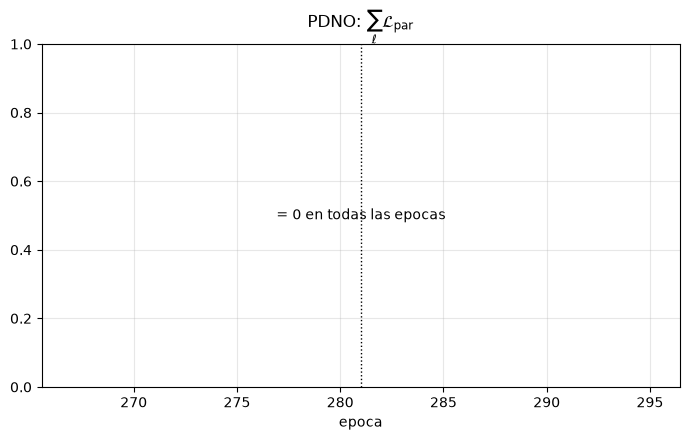

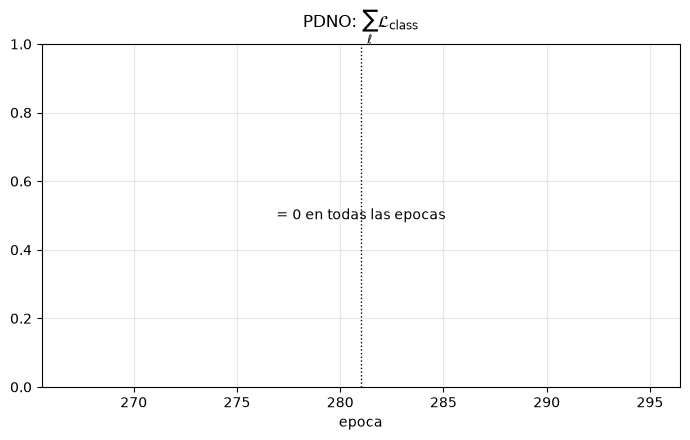

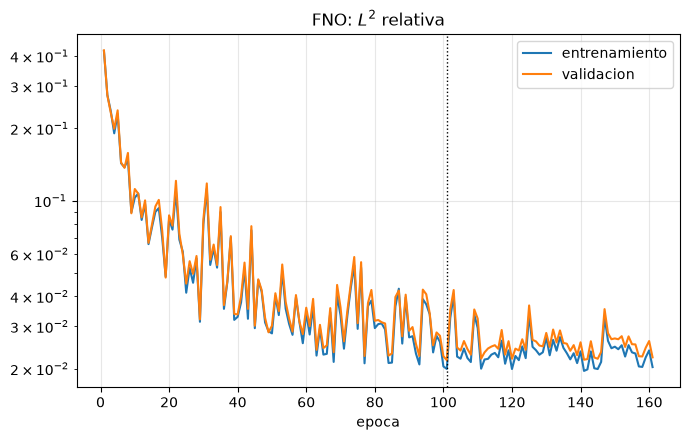

In [48]:
exp_1_5.curves()

## 4. Prueba

PRUEBA -- 20 condiciones iniciales nuevas x 20 tiempos
  PDNO: error relativo L2 = 1.4565e-05  (medio; max 1.4868e-04)
  FNO: error relativo L2 = 1.9137e-02  (medio; max 9.8850e-02)


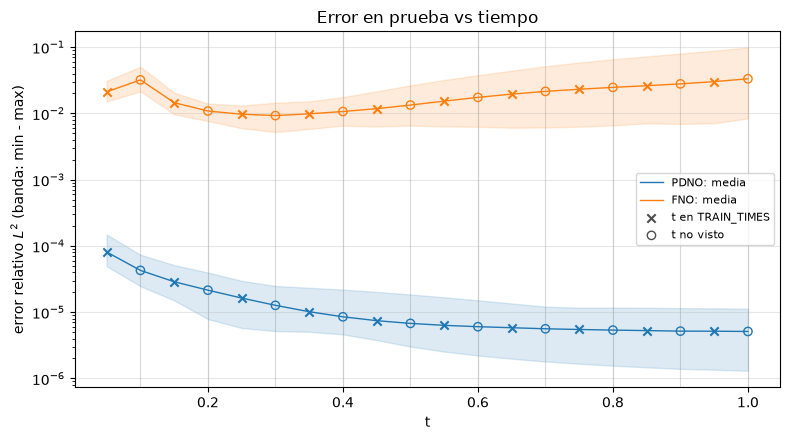

PDNO                 FNO                           
           media       max     media       max en_entrenamiento
t                                                              
0.05    0.000081  0.000149  0.021146  0.031043             True
0.10    0.000043  0.000074  0.032087  0.050551            False
0.15    0.000029  0.000051  0.014554  0.020532             True
0.20    0.000021  0.000040  0.010863  0.014091            False
0.25    0.000016  0.000030  0.009722  0.013149             True
0.30    0.000013  0.000025  0.009274  0.014507            False
0.35    0.000010  0.000023  0.009859  0.015210             True
0.40    0.000009  0.000022  0.010684  0.017641            False
0.45    0.000007  0.000020  0.011792  0.021584             True
0.50    0.000007  0.000019  0.013372  0.026462            False
0.55    0.000006  0.000017  0.015339  0.031985             True
0.60    0.000006  0.000015  0.017471  0.037715            False
0.65    0.000006  0.000014  0.019564  0.044118             True
0.70    0.000006  0.000012  0.021486  0.051523            False
0.75    0.000005  0.000012  0.023186  0.058707             True
0.80    0.000005  0.000012  0.024710  0.065639            False
0.85    0.000005  0.000012  0.026206  0.072597             True
0.90    0.000005  0.000012  0.027917  0.080028            False
0.95    0.000005  0.000011  0.030173  0.088542             True
1.00    0.000005  0.000011  0.033336  0.098850            False
global  0.000015  0.000149  0.019137  0.098850             None

In [49]:
display(exp_1_5.test())

**Campo.**

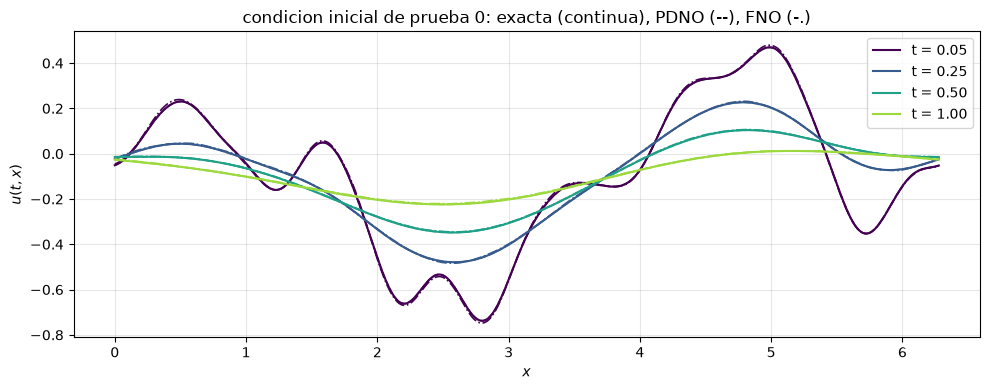

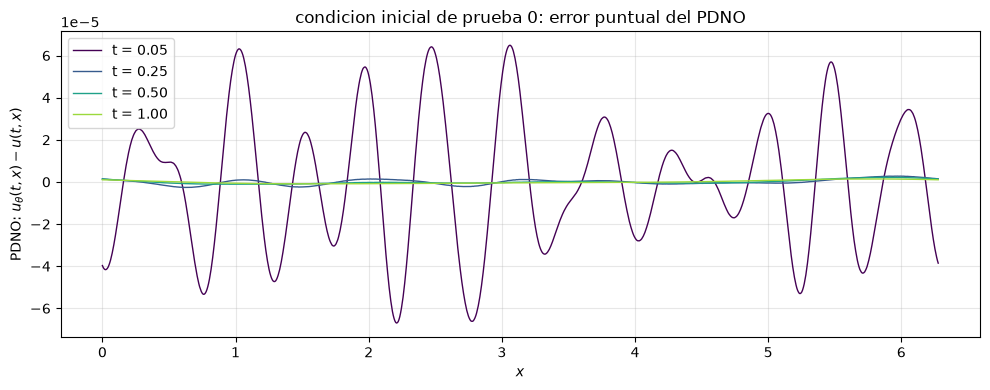

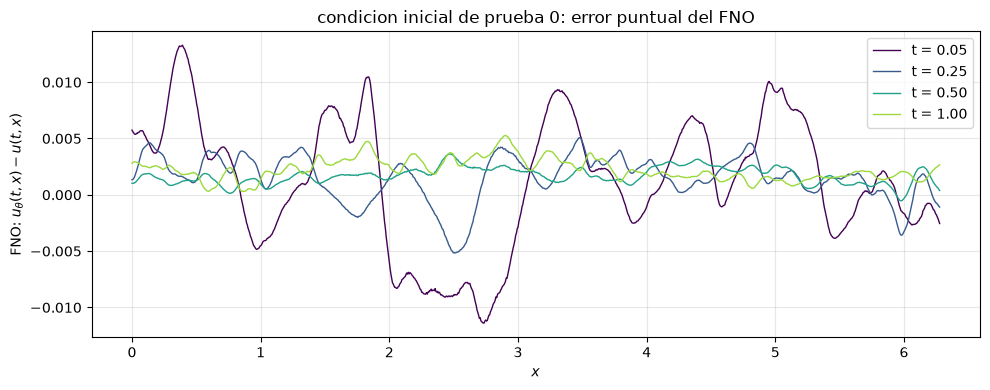

In [50]:
exp_1_5.field_figure()

## 5. Extrapolacion temporal

EXTRAPOLACION -- 20 condiciones iniciales x 21 tiempos en [1, 3]
  PDNO: error relativo L2 = 4.4524e-06  (medio; max 1.5869e-05)
  FNO: error relativo L2 = 4.4152e-01  (medio; max 4.1403e+00)


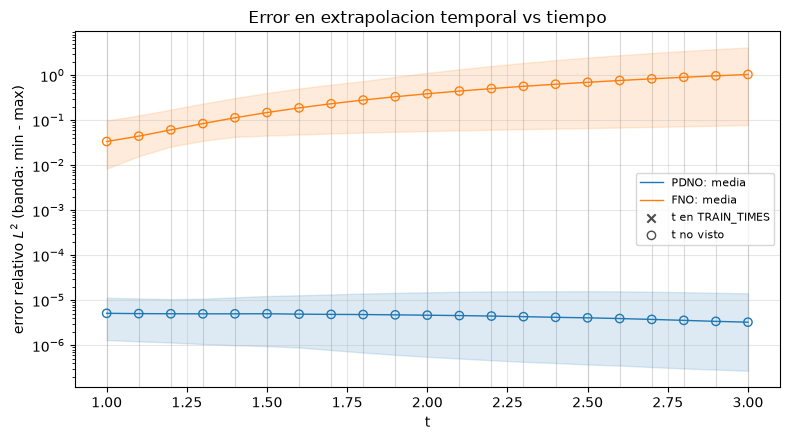

PDNO                 FNO                           
           media       max     media       max en_entrenamiento
t                                                              
1.00    0.000005  0.000011  0.033685  0.098850            False
1.10    0.000005  0.000011  0.044349  0.127976            False
1.20    0.000005  0.000011  0.061129  0.172188            False
1.30    0.000005  0.000011  0.084262  0.233484            False
1.40    0.000005  0.000012  0.113537  0.311162            False
1.50    0.000005  0.000012  0.148443  0.402967            False
1.60    0.000005  0.000013  0.188411  0.506441            False
1.70    0.000005  0.000013  0.232834  0.618537            False
1.80    0.000005  0.000014  0.281191  0.739510            False
1.90    0.000005  0.000015  0.333003  0.921398            False
2.00    0.000005  0.000015  0.387928  1.126371            False
2.10    0.000005  0.000015  0.445581  1.353875            False
2.20    0.000004  0.000016  0.505728  1.603151            False
2.30    0.000004  0.000016  0.568052  1.873165            False
2.40    0.000004  0.000016  0.632266  2.161912            False
2.50    0.000004  0.000016  0.698094  2.467092            False
2.60    0.000004  0.000016  0.765205  2.785827            False
2.70    0.000004  0.000015  0.833363  3.115506            False
2.80    0.000004  0.000015  0.902200  3.452844            False
2.90    0.000003  0.000015  0.971520  3.795476            False
3.00    0.000003  0.000014  1.041075  4.140266            False
global  0.000004  0.000016  0.441517  4.140266             None

In [51]:
display(exp_1_5.extrapolation())

## 6. Invariancia de resolucion

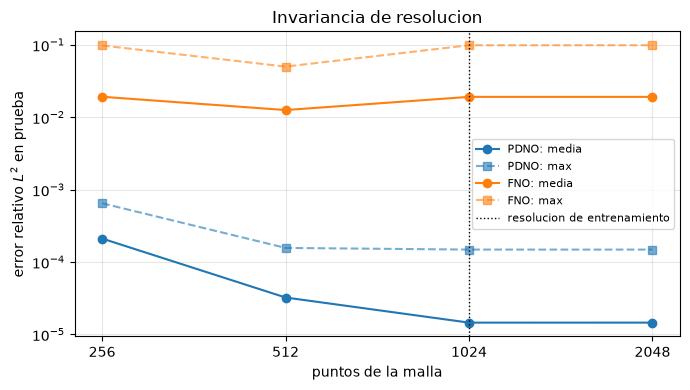

,PDNO media,PDNO max,FNO media,FNO max
resolucion,,,,
256,0.000211,0.000649,0.019197,0.098111
512,0.000032,0.000157,0.012584,0.050126
1024,0.000015,0.000149,0.019137,0.098850
2048,0.000015,0.000149,0.019128,0.098982


In [52]:
display(exp_1_5.resolution_invariance())

## 7. Simbolo y certificacion del PDNO

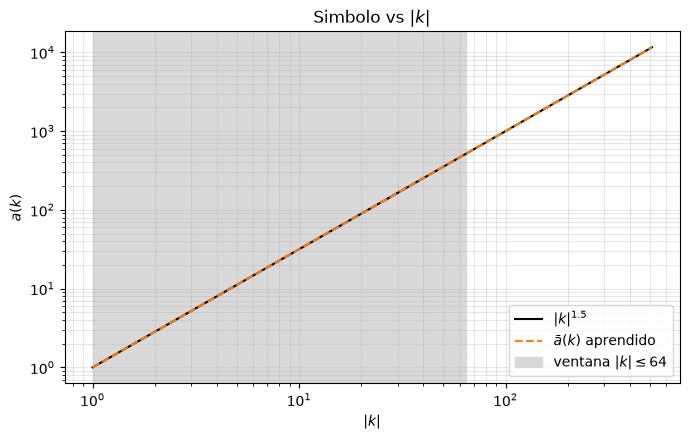

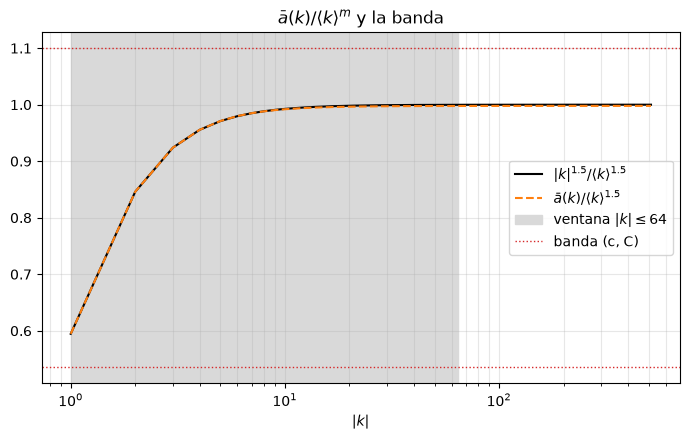

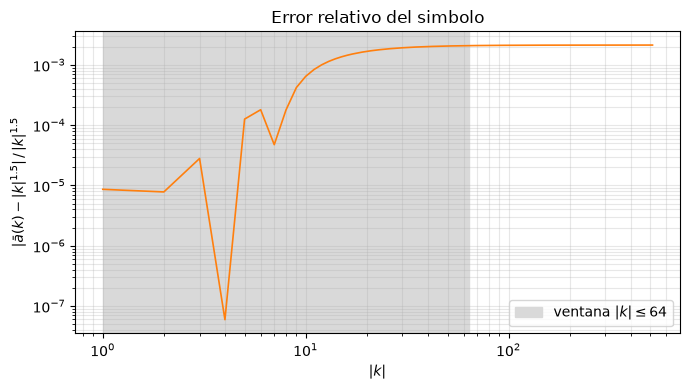

,dentro (|k| <= 64),fuera (|k| > 64)
n,129.000000,896.000000
mse,0.280251,174.772794
rmse,0.529387,13.220166
mae,0.410155,11.244745
max_error,1.067596,24.695511
rel_l2,0.002044,0.002131
error_relativo_medio,0.001603,0.002127
error_relativo_max,0.002085,0.002132


In [53]:
display(exp_1_5.symbol())

In [54]:
display(exp_1_5.certification())

kappa usada = 2.6427


,simbolo,K,region,puntos,max_ratio,satisfecha
0,capa 0,64,dentro,80625,0.654645,True
1,capa 0,128,fuera,160625,0.654645,True
2,capa 0,192,fuera,240625,0.654645,True
3,efectivo,64,dentro,80625,0.654645,True
4,efectivo,128,fuera,160625,0.654645,True
5,efectivo,192,fuera,240625,0.654645,True


In [55]:
display(exp_1_5.symbol_class())

capa 0: consistentes 3 de 3 multiindices
efectivo: consistentes 3 de 3 multiindices
ventana explorada: |k| <= 128 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta


,simbolo,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(128),crecim.(12->128),pendiente,m-|alpha|,estable,consistente
0,capa 0,"(0,)",0,0.955550,0.988262,0.993824,0.997834,1.004035,1.500139,1.5,True,True
1,capa 0,"(1,)",1,1.583476,1.583476,1.583476,1.583476,1.000000,0.497340,0.5,True,True
2,capa 0,"(2,)",2,2.378394,2.378394,2.378394,2.378394,1.000000,-0.505941,-0.5,True,True
3,efectivo,"(0,)",0,0.955550,0.988262,0.993824,0.997834,1.004035,1.500139,1.5,True,True
4,efectivo,"(1,)",1,1.583476,1.583476,1.583476,1.583476,1.000000,0.497340,0.5,True,True
5,efectivo,"(2,)",2,2.378394,2.378394,2.378394,2.378394,1.000000,-0.505941,-0.5,True,True


## 8. Modelo guardado

In [56]:
exp_1_5.save_fno()

modelo guardado en ../results/12_benchmark_fraccionario_1d/alpha_1.5/modelo_fno.pt


PosixPath('../results/12_benchmark_fraccionario_1d/alpha_1.5/modelo_fno.pt')

In [57]:
exp_1_5.check_saved_fno()

FNO: error de prueba (cargado) = 1.913697e-02  |  (entrenado) = 1.913697e-02  |  identicos: True


True

In [6]:
exp_1_0 = experimentos[1.0]
display(exp_1_0.load_data())
resumen_pdno, class_C = exp_1_0.load_pdno()

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
CAMPOS (condicion inicial x tiempo)
  train        : 80 u0 x 10 tiempos = 800 pares, malla (1024,)
  val          : 20 u0 x 10 tiempos = 200 pares, malla (1024,)
  test         : 20 u0 x 20 tiempos = 400 pares, malla (1024,)
  extrapolation: 20 u0 x 21 tiempos = 420 pares, malla (1024,)

k_max = k_cap = 64
entrenamiento :  80 condiciones iniciales x 10 tiempos =  800 pares
validacion    :  20 condiciones iniciales x 10 tiempos =  200 pares
prueba        :  20 condiciones iniciales x 20 tiempos =  400 pares
extrapolacion :  20 condiciones iniciales x 21 tiempos =  420 pares
prueba: min ||u0_prueba - u0_vista|| / ||u0_prueba|| = 1.007  (> 0: d

,condiciones_iniciales,tiempos,pares,t_min,t_max
conjunto,,,,,
entrenamiento,80,10,800,0.05,0.95
validacion,20,10,200,0.05,0.95
prueba,20,20,400,0.05,1.00
extrapolacion,20,21,420,1.00,3.00


PDNO cargado de ../results/08_pdno_fraccionario_1d/alpha_1/modelo.pt
MLP del simbolo        = (128, 128, 128, 128), sin dropout, weight decay 0.0001
(c, C) = (0.6364, 1.0999), m = 1, kappa = theoretical_kappa() = 2.2222
mejor epoca            = 275 de 300
error de prueba        = 3.742844e-05 (recalculado) | 3.742844e-05 (prueba.csv) | coincide: True


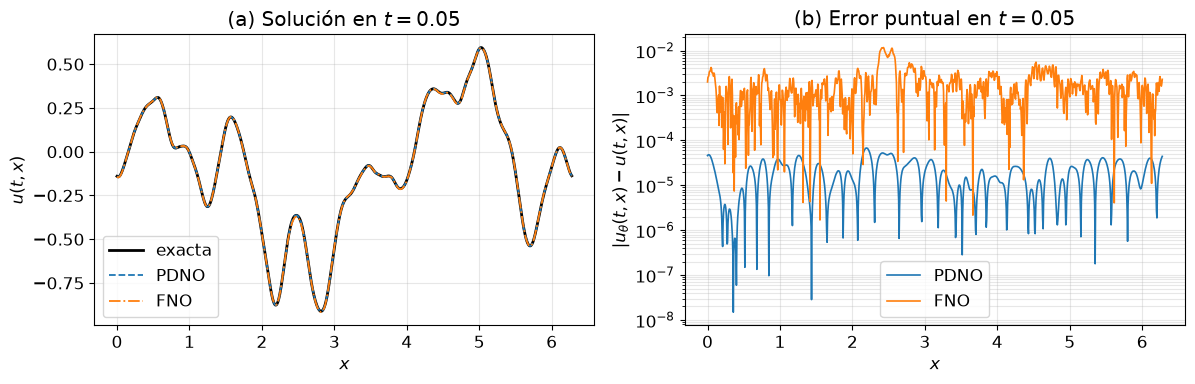

PDNO: error relativo L2 = 6.669e-05
FNO: error relativo L2 = 7.173e-03


In [7]:
# ---------------------------------------------------------------- figura de comparacion
# (a) u exacta, PDNO y FNO en un solo tiempo; (b) |error| de los dos modelos en escala log.
import matplotlib.pyplot as plt
from parabolic_symbol.learning.baseline_training import load_fno_model
from parabolic_symbol.learning.benchmark_experiment import FNO_MODEL_FILE

exp = exp_1_0          # experimento a graficar
i = 0                  # condicion inicial de prueba
j = 0                  # indice del tiempo de prueba (0 -> t = 0.05, 19 -> t = 1.0)

modelos = {
    "PDNO": exp.model_pdno,                                                   # cargado con load_pdno()
    "FNO": load_fno_model(exp.results / FNO_MODEL_FILE, device=exp.device),   # guardado con save_fno()
}

ds = exp.ds
t = ds.test.t[j:j + 1]
exacta = ds.test.u[i, j].numpy()
pred = {}
with torch.no_grad():
    for nombre, m in modelos.items():
        u0 = ds.test.u0[i:i + 1].to(m.device, m.dtype)
        pred[nombre] = m(u0, t.to(m.device, m.dtype))[0].cpu().numpy()

x = 2 * np.pi * np.arange(exp.resolution) / exp.resolution
estilos = {"PDNO": dict(ls="--", color="tab:blue"), "FNO": dict(ls="-.", color="tab:orange")}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# (a) las tres soluciones superpuestas
ax1.plot(x, exacta, "-", color="black", lw=2, label="exacta")
for nombre, p in pred.items():
    ax1.plot(x, p, lw=1.3, label=nombre, **estilos[nombre])
ax1.set_xlabel(r"$x$")
ax1.set_ylabel(r"$u(t, x)$")
ax1.set_title(f"(a) Solución en $t = {t.item():.2f}$")
ax1.legend()
ax1.grid(alpha=0.3)

# (b) error absoluto de los dos modelos en los mismos ejes, escala logaritmica
for nombre, p in pred.items():
    ax2.semilogy(x, np.abs(p - exacta), lw=1.2, label=nombre, color=estilos[nombre]["color"])
ax2.set_xlabel(r"$x$")
ax2.set_ylabel(r"$|u_\theta(t, x) - u(t, x)|$")
ax2.set_title(f"(b) Error puntual en $t = {t.item():.2f}$")
ax2.legend()
ax2.grid(alpha=0.3, which="both")

plt.tight_layout()
fig.savefig(exp.results / f"campo_comparacion_t{t.item():.2f}.png", dpi=200)
plt.show()

for nombre, p in pred.items():
    print(f"{nombre}: error relativo L2 = {np.linalg.norm(p - exacta) / np.linalg.norm(exacta):.3e}")

/tmp/ipykernel_1132/224031939.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


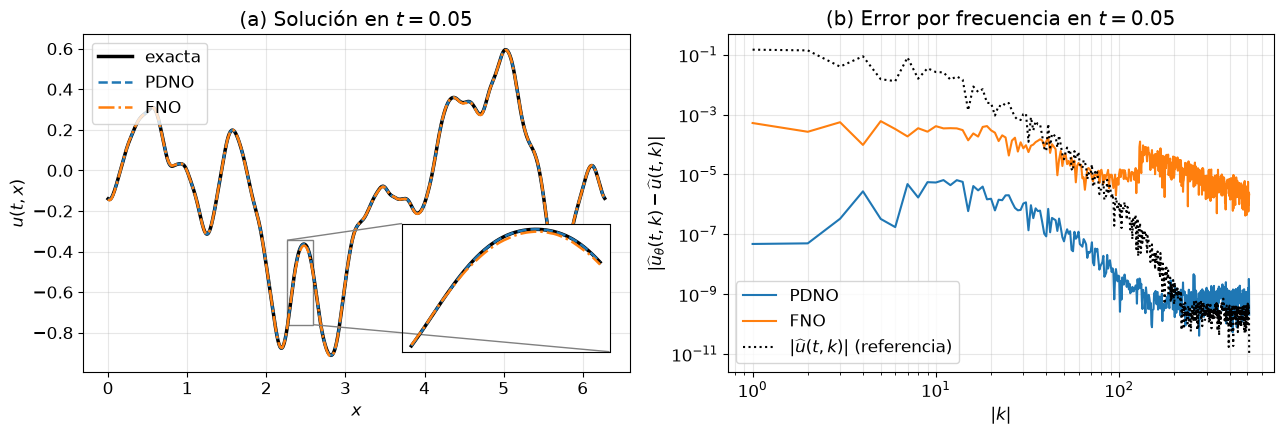

PDNO: error relativo L2 = 6.669e-05
FNO: error relativo L2 = 7.173e-03


In [8]:
# ---------------------------------------------------------------- figura de comparacion (v2)
# (a) solucion con zoom; (b) error en frecuencias |u_theta^(k) - u^(k)| frente a |k|.
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from parabolic_symbol.learning.baseline_training import load_fno_model
from parabolic_symbol.learning.benchmark_experiment import FNO_MODEL_FILE

plt.rcParams.update({"font.size": 12})

exp = exp_1_0          # experimento a graficar
i = 0                  # condicion inicial de prueba
j = 0                  # indice del tiempo de prueba (0 -> t = 0.05)

modelos = {
    "PDNO": exp.model_pdno,
    "FNO": load_fno_model(exp.results / FNO_MODEL_FILE, device=exp.device),
}

ds = exp.ds
t = ds.test.t[j:j + 1]
exacta = ds.test.u[i, j].numpy()
pred = {}
with torch.no_grad():
    for nombre, m in modelos.items():
        u0 = ds.test.u0[i:i + 1].to(m.device, m.dtype)
        pred[nombre] = m(u0, t.to(m.device, m.dtype))[0].cpu().numpy()

N = exp.resolution
x = 2 * np.pi * np.arange(N) / N
colores = {"PDNO": "tab:blue", "FNO": "tab:orange"}
estilos = {"PDNO": "--", "FNO": "-."}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# ---- (a) solucion con zoom
ax1.plot(x, exacta, "-", color="black", lw=2.5, label="exacta")
for nombre, p in pred.items():
    ax1.plot(x, p, estilos[nombre], color=colores[nombre], lw=1.8, label=nombre)
ax1.set_xlabel(r"$x$")
ax1.set_ylabel(r"$u(t,x)$")
ax1.set_title(rf"(a) Solución en $t={t.item():.2f}$")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)

# zona de zoom: alrededor del punto donde el error del FNO es maximo
c = np.argmax(np.abs(pred["FNO"] - exacta))
w = N // 40                                    # semiancho de la ventana
sl = slice(max(c - w, 0), min(c + w, N))
axins = inset_axes(ax1, width="38%", height="38%", loc="lower right", borderpad=1.2)
axins.plot(x[sl], exacta[sl], "-", color="black", lw=2.5)
for nombre, p in pred.items():
    axins.plot(x[sl], p[sl], estilos[nombre], color=colores[nombre], lw=1.8)
axins.set_xticks([]); axins.set_yticks([])
mark_inset(ax1, axins, loc1=2, loc2=4, fc="none", ec="0.5")

# ---- (b) error en el espacio de frecuencias
k = np.fft.rfftfreq(N, d=1.0 / N)              # frecuencias enteras 0, 1, ..., N/2
uh = np.fft.rfft(exacta) / N
for nombre, p in pred.items():
    err_k = np.abs(np.fft.rfft(p) / N - uh)
    ax2.loglog(k[1:], err_k[1:], "-", color=colores[nombre], lw=1.5, label=nombre)
ax2.loglog(k[1:], np.abs(uh[1:]), ":", color="black", lw=1.5, label=r"$|\widehat{u}(t,k)|$ (referencia)")
ax2.set_xlabel(r"$|k|$")
ax2.set_ylabel(r"$|\widehat{u}_\theta(t,k)-\widehat{u}(t,k)|$")
ax2.set_title(rf"(b) Error por frecuencia en $t={t.item():.2f}$")
ax2.legend(loc="lower left")
ax2.grid(alpha=0.3, which="both")

plt.tight_layout()
fig.savefig(exp.results / f"campo_comparacion_t{t.item():.2f}.png", dpi=200, bbox_inches="tight")
plt.show()

for nombre, p in pred.items():
    print(f"{nombre}: error relativo L2 = {np.linalg.norm(p - exacta) / np.linalg.norm(exacta):.3e}")

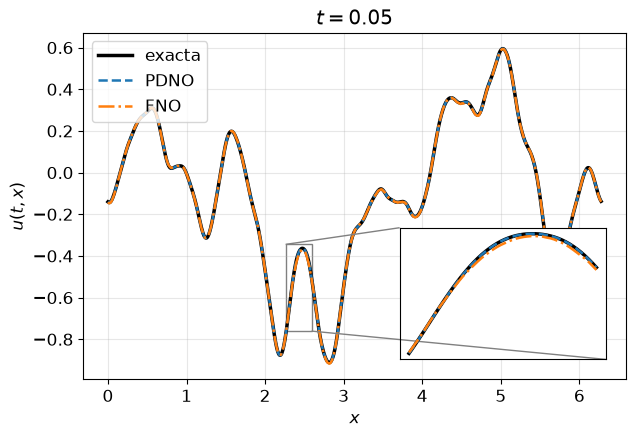

t = 0.05  ->  campo_comparacion_t0.05.png  |  error relativo L2  PDNO: 6.669e-05  |  FNO: 7.173e-03


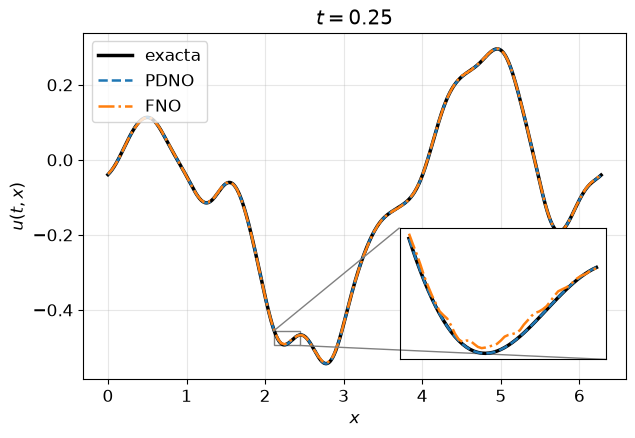

t = 0.25  ->  campo_comparacion_t0.25.png  |  error relativo L2  PDNO: 6.711e-05  |  FNO: 4.086e-03


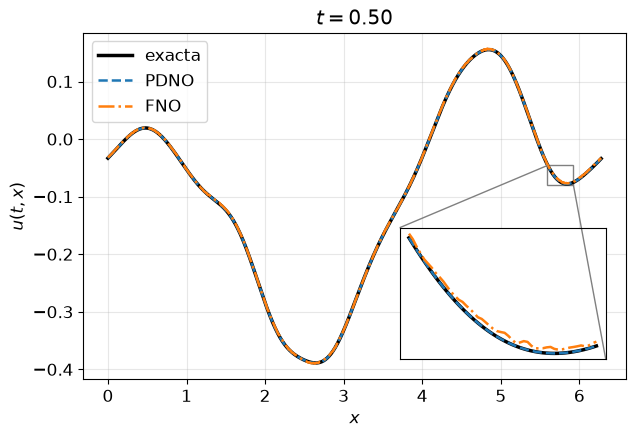

t = 0.50  ->  campo_comparacion_t0.50.png  |  error relativo L2  PDNO: 4.016e-05  |  FNO: 4.711e-03


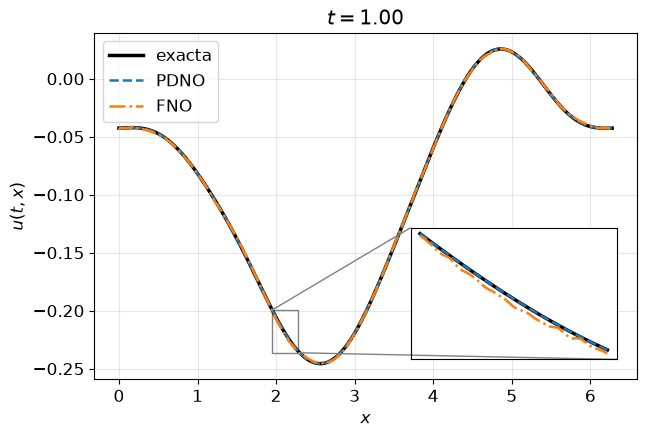

t = 1.00  ->  campo_comparacion_t1.00.png  |  error relativo L2  PDNO: 1.488e-05  |  FNO: 5.030e-03


In [10]:
# ---------------------------------------------------------------- figuras de comparacion (v3)
# Una imagen por tiempo: solucion exacta, PDNO y FNO, con zoom donde el FNO se equivoca mas.
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from parabolic_symbol.learning.baseline_training import load_fno_model
from parabolic_symbol.learning.benchmark_experiment import FNO_MODEL_FILE

plt.rcParams.update({"font.size": 12})

exp = exp_1_0               # experimento a graficar
i = 0                       # condicion inicial de prueba
idx_t = [0, 4, 9, 19]       # indices de tiempo de prueba -> t = 0.05, 0.25, 0.50, 1.00

modelos = {
    "PDNO": exp.model_pdno,
    "FNO": load_fno_model(exp.results / FNO_MODEL_FILE, device=exp.device),
}
colores = {"PDNO": "tab:blue", "FNO": "tab:orange"}
estilos = {"PDNO": "--", "FNO": "-."}

ds = exp.ds
N = exp.resolution
x = 2 * np.pi * np.arange(N) / N

for j in idx_t:
    t = ds.test.t[j:j + 1]
    exacta = ds.test.u[i, j].numpy()
    pred = {}
    with torch.no_grad():
        for nombre, m in modelos.items():
            u0 = ds.test.u0[i:i + 1].to(m.device, m.dtype)
            pred[nombre] = m(u0, t.to(m.device, m.dtype))[0].cpu().numpy()

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(x, exacta, "-", color="black", lw=2.5, label="exacta")
    for nombre, p in pred.items():
        ax.plot(x, p, estilos[nombre], color=colores[nombre], lw=1.8, label=nombre)
    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$u(t,x)$")
    ax.set_title(rf"$t={t.item():.2f}$")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)

    # zoom alrededor del punto donde el error del FNO es maximo
    c = np.argmax(np.abs(pred["FNO"] - exacta))
    w = N // 40                                   # semiancho de la ventana
    sl = slice(max(c - w, 0), min(c + w, N))
    axins = inset_axes(ax, width="38%", height="38%", loc="lower right", borderpad=1.2)
    axins.plot(x[sl], exacta[sl], "-", color="black", lw=2.5)
    for nombre, p in pred.items():
        axins.plot(x[sl], p[sl], estilos[nombre], color=colores[nombre], lw=1.8)
    axins.set_xticks([]); axins.set_yticks([])
    mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="0.5")

    archivo = exp.results / f"campo_comparacion_t{t.item():.2f}.png"
    fig.savefig(archivo, dpi=200, bbox_inches="tight")
    plt.show()

    errores = "  |  ".join(
        f"{nombre}: {np.linalg.norm(p - exacta) / np.linalg.norm(exacta):.3e}" for nombre, p in pred.items()
    )
    print(f"t = {t.item():.2f}  ->  {archivo.name}  |  error relativo L2  {errores}")